# Who Gets to Borrow in Nigeria?
### Banks, loan apps and the common man: the price of credit and who gets it

*Freedom Oboh · data analyst, Lagos · part of my Nigerian economic data series*

In my last project I showed that ₦100,000 left in a Nigerian savings account since 2006 lost most of its value to inflation. Saving lost.

So this project asks the other side of the question: **if saving loses money in Nigeria, what does it cost to borrow? And who actually gets to borrow at all?**

I follow two people the whole way through. They are illustrations for this case study, not real people:

- **Tunde**, a salary earner in Lagos. His generator packs up and he needs **₦100,000 for one month**.
- **Amaka**, who runs a provisions shop. She needs **₦500,000 for six months** to restock before the festive season.

| Chapter | Question |
|---|---|
| 1 | What do banks charge? |
| 2 | Is borrowing cheap or expensive once you remove inflation? |
| 3 | Does the CBN's rate reach the street? |
| 4 | Who gets the credit: government or the private sector? |
| 5 | Why lend to Amaka when government pays well? |
| 6 | The loan app on Tunde's phone |
| 7 | So where does the common man go? |
| 8 | What happens when Tunde misses the due date? |
| 9 | Do banks pass on rate cuts as fast as rate rises? |
| 10 | Save first, or borrow now? |
| 11 | What I learned, and what to watch |

*This is a historical data analysis and a learning project, not financial advice.*

## Setup and data

The data comes from three CBN feeds: money market rates, money and credit statistics, and inflation. `src/fetch_cbn.py` downloads them and saves each pull with its date in `data/raw/`. The notebook reads the latest saved pull, so every run uses the same numbers until I pull again.

To refresh the data, run `python src/fetch_cbn.py` from the project folder, or set `REFRESH = True` below.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from IPython.display import Markdown, display

import fetch_cbn, clean, loan_math, style
style.apply()
pd.set_option("display.width", 120)

REFRESH = False  # True = download fresh data from the CBN (stops with an error if a feed fails)
if REFRESH:
    fetch_cbn.fetch_all()

for name in fetch_cbn.FEEDS:
    print(f"{name:13s} -> {fetch_cbn.latest_raw(name).name}")

money_market  -> money_market_2026-11-05.json
money_credit  -> money_credit_2026-11-05.json
inflation     -> inflation_2026-11-05.json


In [2]:
mm = clean.load_money_market()
credit = clean.load_credit()
infl = clean.load_inflation()
panel = clean.build_panel()
p = panel.set_index("month")

FIRST, LAST = p.index[0], p.index[-1]
print(f"Money market records: {len(mm)}  ({mm['month'].min():%b %Y} to {mm['month'].max():%b %Y})")
print(f"Credit records (monthly, from 2006): {len(credit)}")
print(f"Inflation records (from 2006): {len(infl)}")
print(f"Panel: {len(panel)} months, {FIRST:%b %Y} to {LAST:%b %Y}")

Money market records: 249  (Jan 2006 to Sep 2026)
Credit records (monthly, from 2006): 248
Inflation records (from 2006): 249
Panel: 249 months, Jan 2006 to Sep 2026


### Data checks

Before any chart, I check what's missing, what's odd, and whether the latest month matches the CBN's published figures.

In [3]:
gaps = {
    "Money market: months with no record": list(clean.missing_months(mm, FIRST, LAST).strftime("%b %Y")),
    "Money market: T-bill rate shown as 0.00 (treated as missing)": list(mm.loc[mm["treasuryBill_zero_fixed"], "month"].dt.strftime("%b %Y")),
    "Money & credit: months with no record": list(clean.missing_months(credit, FIRST, LAST).strftime("%b %Y")),
    "Inflation: June 2025 duplicate of May fixed": list(infl.loc[infl["june_2025_fixed"], "month"].dt.strftime("%b %Y")),
}
for label, months in gaps.items():
    print(f"{label}: {', '.join(months) if months else 'none'}")

Money market: months with no record: none
Money market: T-bill rate shown as 0.00 (treated as missing): Dec 2017, Dec 2018
Money & credit: months with no record: Mar 2026
Inflation: June 2025 duplicate of May fixed: Jun 2025


In [4]:
# Spot-check the latest month against the figures in the brief (CLAUDE.md section 9)
latest = p.loc[LAST]
spot = pd.DataFrame({
    "notebook": [latest["primeLending"], latest["maxLending"], latest["mpr"], latest["treasuryBill"],
                 latest["creditToPrivateSector"] / 1e6, latest["creditToGovernment"] / 1e6],
    "expected": [19.04, 32.62, 23.00, 16.24, 83.93, 39.40],
}, index=["Prime lending (%)", "Max lending (%)", "MPR (%)", "T-bill (%)",
          "Credit to private sector (₦tn)", "Credit to government (₦tn)"])
spot["match"] = (spot["notebook"].round(2) == spot["expected"])
print(f"Spot-check for {LAST:%B %Y}")
spot.round(2)

Spot-check for September 2026


,notebook,expected,match
Prime lending (%),19.04,19.04,True
Max lending (%),32.62,32.62,True
MPR (%),23.00,23.00,True
T-bill (%),16.24,16.24,True
Credit to private sector (₦tn),83.93,83.93,True
Credit to government (₦tn),39.40,39.40,True


> **Under the hood: the policy rate before Dec 2006 (trap 1).** The feed shows the MPR (Monetary Policy Rate) as 0 from Jan to Nov 2006. That isn't a 0% rate. The MPR only started in Dec 2006, when it replaced the older MRR (Minimum Rediscount Rate). I join them into one `policy_rate` column: MRR up to Nov 2006, MPR from Dec 2006. The table below shows the switch.

In [5]:
p.loc["2006-09-01":"2007-01-01", ["mrr", "mpr", "policy_rate", "policy_rate_source"]]

,mrr,mpr,policy_rate,policy_rate_source
month,,,,
2006-09-01,14.0,0.0,14.0,MRR
2006-10-01,14.0,0.0,14.0,MRR
2006-11-01,14.0,0.0,14.0,MRR
2006-12-01,NaN,10.0,10.0,MPR
2007-01-01,NaN,10.0,10.0,MPR


> **Under the hood: missing months (trap 4).** The brief expected about three months missing from the money market feed. When I checked, all 249 months from Jan 2006 to Sep 2026 are there. The gaps are elsewhere. The T-bill rate is printed as 0.00 in two December months, which can't be right next to double-digit rates either side, so I treat those as missing. The money and credit feed skips one month completely. For **charts only**, I fill these gaps by drawing a straight line between the months on either side (`*_filled` columns). **Regressions and correlations use the unfilled data**, so no made-up month affects a result.

---
## Chapter 1: The price tag at the bank

**What does a bank charge to lend you money?**

The CBN publishes two lending rates each month:

- **Prime lending rate**: the average rate banks charge their best customers, usually big companies with strong accounts and collateral (something the bank can take if you don't pay, like property).
- **Maximum lending rate**: the average of the highest rates banks charge, which is what riskier borrowers face.

The gap between the two is the **risk premium**: the extra a small or risky borrower pays compared with a big, trusted company.

I expected the gap to move up and down with the economy. The data showed something steadier and more worrying.

In [6]:
gap = p["maxLending"] - p["primeLending"]
yearly = pd.DataFrame({
    "prime": p["primeLending"].resample("YS").mean(),
    "max": p["maxLending"].resample("YS").mean(),
    "gap": gap.resample("YS").mean(),
}).round(1)
yearly.index = yearly.index.year
yearly.index.name = "year (average)"
yearly.T

year (average),2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
prime,16.9,16.9,15.1,19.0,17.6,16.0,16.8,16.7,16.5,16.8,...,17.6,16.9,15.6,13.3,11.5,12.3,14.0,16.3,17.9,19.0
max,18.4,18.4,18.7,22.6,22.5,22.4,23.8,24.7,25.7,26.7,...,30.6,31.1,30.8,29.6,28.1,28.1,28.0,29.2,29.7,33.5
gap,1.5,1.4,3.6,3.6,4.9,6.4,7.0,8.0,9.2,9.9,...,13.0,14.2,15.1,16.3,16.6,15.8,14.0,12.9,11.9,14.4


In [7]:
g_first, g_last = gap.iloc[0], gap.iloc[-1]
g_peak_month, g_peak = gap.idxmax(), gap.max()
prime_mean, max_first, max_last = p["primeLending"].mean(), p["maxLending"].iloc[0], p["maxLending"].iloc[-1]
prime_first, prime_last = p["primeLending"].iloc[0], p["primeLending"].iloc[-1]

print(f"Gap in {FIRST:%b %Y}: {g_first:.1f} points.  Gap in {LAST:%b %Y}: {g_last:.1f} points.")
print(f"Widest gap: {g_peak:.1f} points in {g_peak_month:%b %Y}.  Average gap: {gap.mean():.1f} points.")
print(f"Prime rate: {prime_first:.2f}% -> {prime_last:.2f}% (average {prime_mean:.1f}%).")
print(f"Maximum rate: {max_first:.2f}% -> {max_last:.2f}%.")

Gap in Jan 2006: 1.5 points.  Gap in Sep 2026: 13.6 points.
Widest gap: 19.0 points in Feb 2022.  Average gap: 10.0 points.
Prime rate: 16.69% -> 19.04% (average 16.1%).
Maximum rate: 18.23% -> 32.62%.


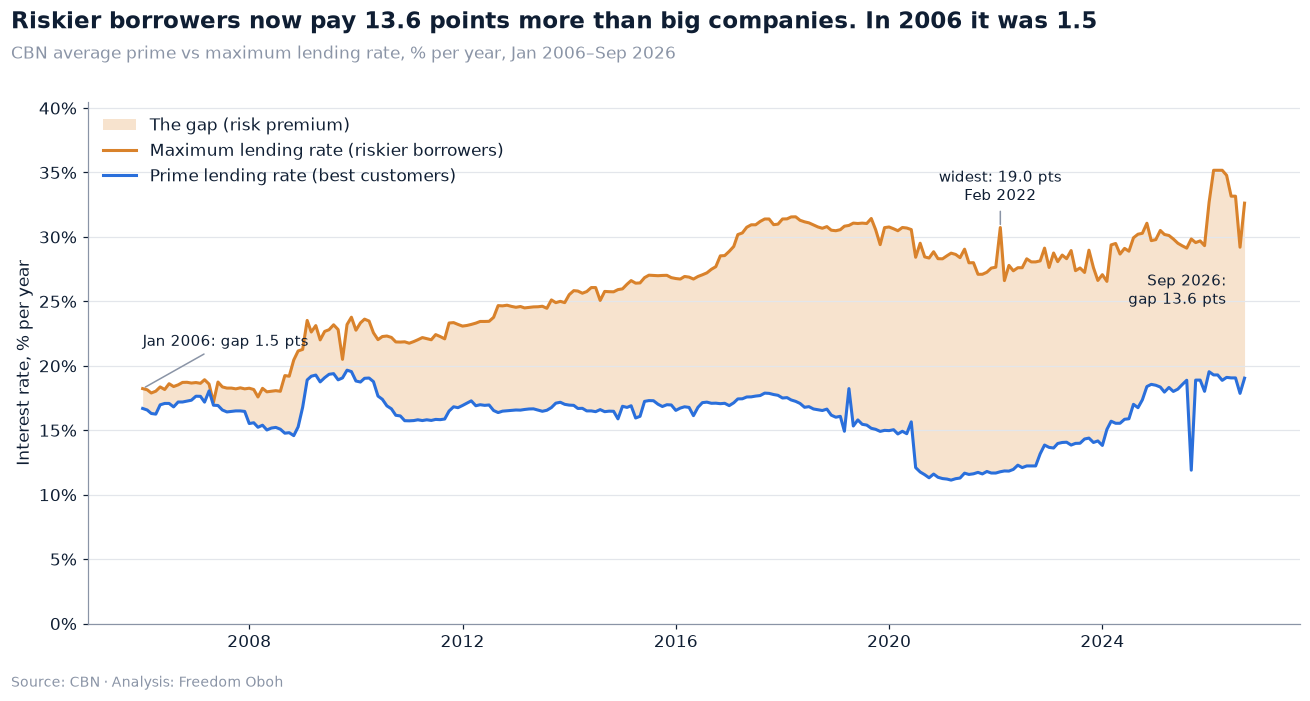

In [8]:
fig, ax = plt.subplots(figsize=(12, 6.3))
x = p.index
ax.fill_between(x, p["primeLending"], p["maxLending"], color=style.PALE_ORANGE, alpha=0.8, linewidth=0,
                label="The gap (risk premium)")
ax.plot(x, p["maxLending"], color=style.ORANGE, linewidth=2, label="Maximum lending rate (riskier borrowers)")
ax.plot(x, p["primeLending"], color=style.BLUE, linewidth=2, label="Prime lending rate (best customers)")

ax.annotate(f"{FIRST:%b %Y}: gap {g_first:.1f} pts", xy=(FIRST, p.loc[FIRST, "maxLending"]),
            xytext=(0, 28), textcoords="offset points", ha="left", fontsize=10, color=style.NAVY,
            arrowprops={"arrowstyle": "-", "color": style.GREY})
mid = (p.loc[LAST, "primeLending"] + p.loc[LAST, "maxLending"]) / 2
ax.annotate(f"{LAST:%b %Y}:\ngap {g_last:.1f} pts", xy=(LAST, mid), xytext=(-12, 0), textcoords="offset points",
            ha="right", va="center", fontsize=10, color=style.NAVY)
ax.annotate(f"widest: {g_peak:.1f} pts\n{g_peak_month:%b %Y}",
            xy=(g_peak_month, p.loc[g_peak_month, "maxLending"]), xytext=(0, 18), textcoords="offset points",
            ha="center", fontsize=10, color=style.NAVY, arrowprops={"arrowstyle": "-", "color": style.GREY})

ax.set_ylim(0, p["maxLending"].max() * 1.15)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("Interest rate, % per year")
ax.legend(loc="upper left")
style.titles(fig, ax,
             f"Riskier borrowers now pay {g_last:.1f} points more than big companies. In {FIRST:%Y} it was {g_first:.1f}",
             f"CBN average prime vs maximum lending rate, % per year, {FIRST:%b %Y}–{LAST:%b %Y}")
style.finish(fig, "01_prime_vs_max.png")
plt.show()

In [9]:
print(f"In {LAST:%B %Y}, a big company borrowing at the prime rate paid about {prime_last:.1f}% a year.")
print(f"Amaka, priced near the maximum rate, would pay about {max_last:.1f}% a year: "
      f"{g_last:.1f} points more, for the same naira.")
print(f"In {FIRST:%Y} the difference was only {g_first:.1f} points.")

In September 2026, a big company borrowing at the prime rate paid about 19.0% a year.
Amaka, priced near the maximum rate, would pay about 32.6% a year: 13.6 points more, for the same naira.
In 2006 the difference was only 1.5 points.


**What this means for Tunde and Amaka.** Big companies borrow near the prime rate. Amaka pays closer to the maximum rate, if she gets a loan at all. Over 20 years the prime rate went up and down and ended only a little higher than it started. The maximum rate kept climbing. Being a "risky" borrower in Nigeria costs far more today than it did in 2006.

> **Under the hood: these are averages (trap 7).** The CBN prime and maximum rates are averages of what banks report. They are not a price list. One borrower can be offered more than the maximum average or less than the prime. Many small borrowers are never offered a rate at all. Read the lines as the general level of bank pricing, not as Tunde's or Amaka's actual quote.

---
## Chapter 2: Is borrowing cheap or expensive once you remove inflation?

**If prices rise 20% this year and your loan costs 18%, did the loan really cost you anything?**

When prices rise fast, the naira you pay back is worth less than the naira you borrowed. So the honest price of a loan is the **real rate**: the interest rate after inflation is taken out. I use the same formula as in the savings project (the Fisher equation):

> real rate = (1 + loan rate) ÷ (1 + inflation) − 1

If the real rate is **negative**, borrowers came out ahead (inflation was higher than the loan rate): the money they repaid could buy less than the money they borrowed. If it is high and positive, the loan is crushing.

I expected borrowers to come out ahead often, because savers lost so badly in my last project. The data showed it isn't that simple.

In [10]:
def real_rate(nominal_pct, inflation_pct):
    return ((1 + nominal_pct / 100) / (1 + inflation_pct / 100) - 1) * 100

real = pd.DataFrame({
    "prime": real_rate(p["primeLending"], p["inflation"]),
    "max": real_rate(p["maxLending"], p["inflation"]),
    "savings": real_rate(p["savingsDeposit"], p["inflation"]),
})


def negative_runs(series):
    # Each unbroken run of negative months: start, end, length, lowest value
    neg = series < 0
    run_id = (neg != neg.shift()).cumsum()
    rows = [{"from": g.index[0], "to": g.index[-1], "months": len(g), "lowest real rate (%)": round(g.min(), 1)}
            for _, g in series[neg].groupby(run_id[neg])]
    return pd.DataFrame(rows)


n = len(real)
summary = pd.DataFrame({
    "months below zero": (real < 0).sum(),
    "share of months": ((real < 0).mean() * 100).round(0).astype(int).astype(str) + "%",
    "lowest": real.min().round(1),
    "highest": real.max().round(1),
    f"{LAST:%b %Y}": real.iloc[-1].round(1),
}).rename(index={"prime": "Real prime lending rate", "max": "Real maximum lending rate", "savings": "Real savings rate"})
summary

,months below zero,share of months,lowest,highest,Sep 2026
Real prime lending rate,72,29%,-13.7,13.7,3.8
Real maximum lending rate,14,6%,-3.9,18.1,15.7
Real savings rate,249,100%,-20.8,-0.0,-8.1


In [11]:
prime_runs = negative_runs(real["prime"])
longest = prime_runs.loc[prime_runs["months"].idxmax()]
neg_prime, neg_max, neg_sav = (real["prime"] < 0).sum(), (real["max"] < 0).sum(), (real["savings"] < 0).sum()
low_month, low_val = real["prime"].idxmin(), real["prime"].min()

print(f"At the prime rate, borrowers came out ahead (inflation was higher than the loan rate) in {neg_prime} of {n} months ({neg_prime / n:.0%}).")
print(f"{longest['months']} of those came in one stretch: {longest['from']:%b %Y} to {longest['to']:%b %Y}.")
print(f"Lowest: {low_val:.1f}% in {low_month:%b %Y}.")
print(f"At the MAXIMUM rate, borrowers came out ahead (inflation was higher than the loan rate) in only {neg_max} months.")
print(f"\nNegative stretches for the prime rate:")
prime_runs.assign(**{"from": prime_runs["from"].dt.strftime("%b %Y"), "to": prime_runs["to"].dt.strftime("%b %Y")})

At the prime rate, borrowers came out ahead (inflation was higher than the loan rate) in 72 of 249 months (29%).
64 of those came in one stretch: Jul 2020 to Oct 2025.
Lowest: -13.7% in May 2024.
At the MAXIMUM rate, borrowers came out ahead (inflation was higher than the loan rate) in only 14 months.

Negative stretches for the prime rate:


,from,to,months,lowest real rate (%)
0,Nov 2008,Nov 2008,1,-0.2
1,Aug 2016,Feb 2017,7,-1.5
2,Jul 2020,Oct 2025,64,-13.7


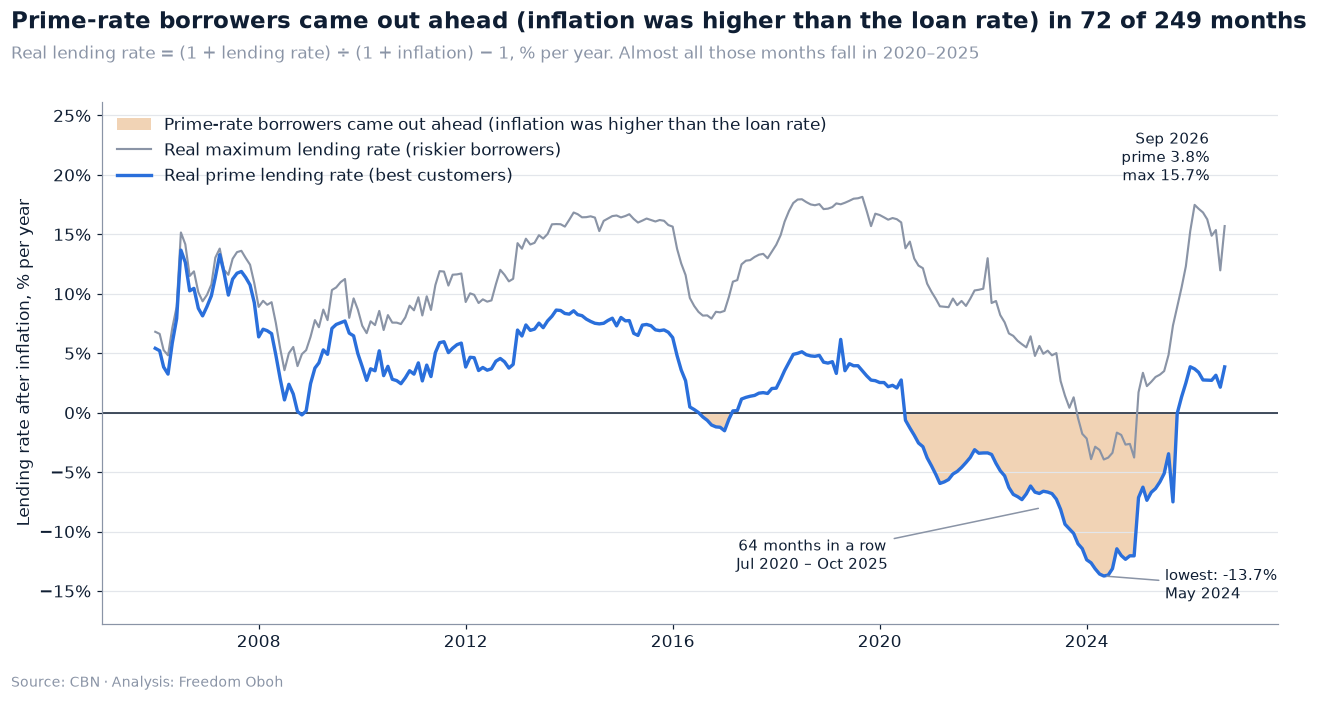

In [12]:
fig, ax = plt.subplots(figsize=(12, 6.3))
x = real.index
ax.axhline(0, color=style.NAVY, linewidth=1)
ax.fill_between(x, real["prime"], 0, where=real["prime"] < 0, interpolate=True, color=style.ORANGE, alpha=0.35,
                linewidth=0, label="Prime-rate borrowers came out ahead (inflation was higher than the loan rate)")
ax.plot(x, real["max"], color=style.GREY, linewidth=1.4, label="Real maximum lending rate (riskier borrowers)")
ax.plot(x, real["prime"], color=style.BLUE, linewidth=2.2, label="Real prime lending rate (best customers)")

mid = longest["from"] + (longest["to"] - longest["from"]) / 2
ax.annotate(f"{longest['months']} months in a row\n{longest['from']:%b %Y} – {longest['to']:%b %Y}",
            xy=(mid, -8), xytext=(-150, -40), textcoords="offset points", ha="center", fontsize=10,
            color=style.NAVY, arrowprops={"arrowstyle": "-", "color": style.GREY})
ax.annotate(f"lowest: {low_val:.1f}%\n{low_month:%b %Y}", xy=(low_month, low_val), xytext=(40, -6),
            textcoords="offset points", fontsize=10, color=style.NAVY, va="center",
            arrowprops={"arrowstyle": "-", "color": style.GREY})
ax.annotate(f"{LAST:%b %Y}\nprime {real['prime'].iloc[-1]:.1f}%\nmax {real['max'].iloc[-1]:.1f}%",
            xy=(LAST, real["max"].iloc[-1]), xytext=(-10, 30), textcoords="offset points", ha="right",
            fontsize=10, color=style.NAVY)

ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("Lending rate after inflation, % per year")
ax.set_ylim(min(real["prime"].min(), real["max"].min()) - 4, real["max"].max() + 8)
ax.legend(loc="upper left", ncols=1)
style.titles(fig, ax,
             f"Prime-rate borrowers came out ahead (inflation was higher than the loan rate) in {neg_prime} of {n} months",
             f"Real lending rate = (1 + lending rate) ÷ (1 + inflation) − 1, % per year. Almost all those months fall in {longest['from']:%Y}–{longest['to']:%Y}")
style.finish(fig, "02_real_lending_rate.png")
plt.show()

### Saving and borrowing: two sides of the same rate

In the savings project, savers lost to inflation. Does that mean borrowers gained? Only partly. The bank sits in the middle and keeps a margin, so savers and borrowers don't simply swap places.

In [13]:
both = ((real["savings"] < 0) & (real["prime"] < 0)).sum()
saver_lost_borrower_paid = ((real["savings"] < 0) & (real["prime"] >= 0)).sum()
spread = (p["primeLending"] - p["savingsDeposit"])
print(f"Savers lost to inflation in {neg_sav} of {n} months (savings account rate).")
print(f"In {both} of those months, prime-rate borrowers came out ahead (inflation was higher than the loan rate).")
print(f"In the other {saver_lost_borrower_paid} months, savers lost AND borrowers still paid a positive real rate.")
print(f"Average gap between the prime lending rate and the savings rate: {spread.mean():.1f} points "
      f"({spread.iloc[-1]:.1f} in {LAST:%b %Y}).")
print(f"Correlation between the real savings rate and the real prime rate: {real['savings'].corr(real['prime']):.2f}")

Savers lost to inflation in 249 of 249 months (savings account rate).
In 72 of those months, prime-rate borrowers came out ahead (inflation was higher than the loan rate).
In the other 177 months, savers lost AND borrowers still paid a positive real rate.
Average gap between the prime lending rate and the savings rate: 12.6 points (13.7 in Sep 2026).
Correlation between the real savings rate and the real prime rate: 0.96


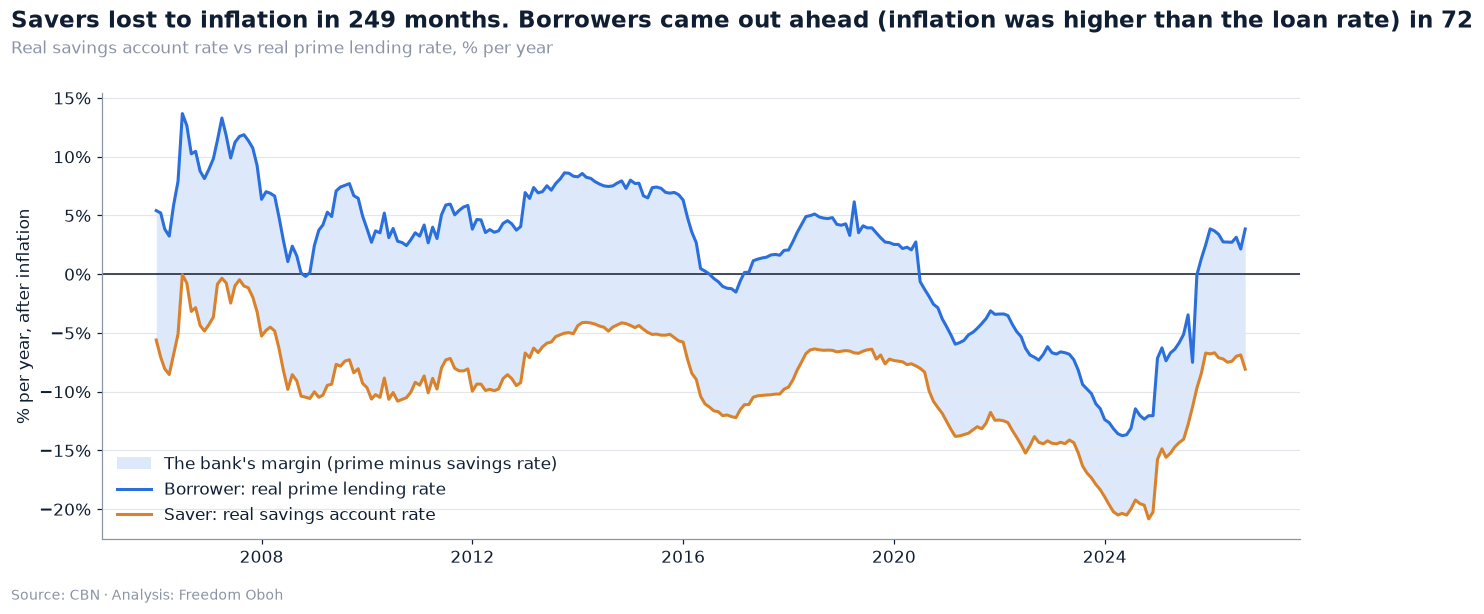

In [14]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.axhline(0, color=style.NAVY, linewidth=1)
ax.fill_between(x, real["savings"], real["prime"], color=style.PALE_BLUE, alpha=0.7, linewidth=0,
                label="The bank's margin (prime minus savings rate)")
ax.plot(x, real["prime"], color=style.BLUE, linewidth=2, label="Borrower: real prime lending rate")
ax.plot(x, real["savings"], color=style.ORANGE, linewidth=2, label="Saver: real savings account rate")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("% per year, after inflation")
ax.legend(loc="lower left")
style.titles(fig, ax,
             f"Savers lost to inflation in {neg_sav} months. Borrowers came out ahead (inflation was higher than the loan rate) in {both}",
             "Real savings account rate vs real prime lending rate, % per year")
style.finish(fig, "02b_savers_vs_borrowers.png")
plt.show()

In [15]:
r_prime_last, r_max_last = real["prime"].iloc[-1], real["max"].iloc[-1]
print(f"{LAST:%B %Y}: inflation {p['inflation'].iloc[-1]:.2f}%.")
print(f"A big company at the prime rate pays about {r_prime_last:.1f}% a year above inflation.")
print(f"Amaka, near the maximum rate, would pay about {r_max_last:.1f}% a year above inflation.")

September 2026: inflation 14.63%.
A big company at the prime rate pays about 3.8% a year above inflation.
Amaka, near the maximum rate, would pay about 15.7% a year above inflation.


**What this means for Tunde and Amaka.** For about five years, from 2020 to 2025, inflation ran so fast that anyone who got a bank loan at the prime rate repaid less, in real terms, than they borrowed. But "anyone who got a bank loan" means mostly big companies. At the maximum rate, the rate closer to Amaka's, borrowers came out ahead (inflation was higher than the loan rate) in only a handful of months. Now that inflation has come down, the real cost has jumped back up, and for a small borrower it is heavy. And for savers like Tunde's savings account, there was no good month at all.

> **Under the hood: real rates.** I use the exact Fisher formula, not "rate minus inflation". The inflation figure is year-on-year (prices compared with the same month last year), so this is a backward-looking real rate: it compares this month's loan rate with the past year's inflation. A borrower's true real cost depends on inflation over the life of their loan, which nobody knows in advance. The inflation series is the CBN feed with the same treatment as in my savings project: the NBS 2025 revision as published, the January 2025 CPI rebasing, and the June 2025 duplicate replaced by the midpoint of May and July.

---
## Chapter 3: Does the CBN's lever reach the street?

**When the Central Bank raises its rate, does Amaka's loan get more expensive? How much, and how fast?**

The **MPR (Monetary Policy Rate)** is the CBN's main interest rate. It's the "lever" the CBN pulls to cool inflation (raise it) or support growth (cut it). In theory, when the MPR goes up, banks' own cost of money goes up and they pass it on to borrowers.

I test that three ways:
1. **One real hiking cycle**: the big rise in the MPR from 2022 to 2024. How much did lending rates move?
2. **Cross-correlation**: does a change in the MPR line up with a change in lending rates 0, 1, 2 … 12 months later?
3. **A regression with lags**: on average, how many points of each 1-point MPR change reach the prime and maximum lending rates, month by month, over a year?

I expected most of a rate rise to reach borrowers within a few months. The data showed much less, much more slowly.

In [16]:
# Month-on-month changes, from the UNFILLED data (trap 4)
chg = p[["policy_rate", "primeLending", "maxLending"]].diff()
# Dec 2006 is the switch from MRR (14%) to MPR (10%). That's a change of instrument, not a policy move.
chg.loc["2006-12-01", "policy_rate"] = np.nan

moves = chg["policy_rate"][chg["policy_rate"].fillna(0) != 0]
print(f"Policy rate changes, {FIRST:%b %Y}–{LAST:%b %Y}: {len(moves)} "
      f"({(moves > 0).sum()} rises, {(moves < 0).sum()} cuts)")

Policy rate changes, Jan 2006–Sep 2026: 40 (29 rises, 11 cuts)


### 1. The 2022–2024 hiking cycle

Starting in May 2022, the CBN raised the MPR again and again. I measure from the month before the first rise to the month of the last rise, then look 12 months further on to give banks time to catch up.

In [17]:
pr = p["policy_rate"]
hikes = moves["2022-01-01":"2025-06-01"]
cycle_start = hikes.index[0] - pd.DateOffset(months=1)
cycle_end = hikes[hikes > 0].index[-1]
after = cycle_end + pd.DateOffset(months=12)

cycle = pd.DataFrame({
    m.strftime("%b %Y"): p.loc[m, ["policy_rate", "primeLending", "maxLending"]]
    for m in [cycle_start, cycle_end, after]
}).T
cycle.columns = ["MPR (%)", "Prime lending (%)", "Max lending (%)"]

X = pr[cycle_end] - pr[cycle_start]
prime_move_end = p.loc[cycle_end, "primeLending"] - p.loc[cycle_start, "primeLending"]
prime_move_after = p.loc[after, "primeLending"] - p.loc[cycle_start, "primeLending"]
max_move_after = p.loc[after, "maxLending"] - p.loc[cycle_start, "maxLending"]

print(f"MPR: {pr[cycle_start]:.2f}% ({cycle_start:%b %Y}) -> {pr[cycle_end]:.2f}% ({cycle_end:%b %Y}): +{X:.2f} points "
      f"in {(hikes > 0).sum()} rises.")
print(f"Prime lending rate rose {prime_move_end:+.2f} points by {cycle_end:%b %Y} "
      f"and {prime_move_after:+.2f} points by {after:%b %Y} ({prime_move_after / X:.0%} of the MPR rise).")
print(f"Maximum lending rate rose {max_move_after:+.2f} points by {after:%b %Y} ({max_move_after / X:.0%}).")
cycle.round(2)

MPR: 11.50% (Apr 2022) -> 27.50% (Nov 2024): +16.00 points in 14 rises.
Prime lending rate rose +6.56 points by Nov 2024 and +7.06 points by Nov 2025 (44% of the MPR rise).
Maximum lending rate rose +1.90 points by Nov 2025 (12%).


,MPR (%),Prime lending (%),Max lending (%)
Apr 2022,11.5,11.83,27.79
Nov 2024,27.5,18.39,31.06
Nov 2025,27.0,18.89,29.69


### 2. Cross-correlation at lags 0–12 months

A correlation near 1 at lag *k* would mean "when the MPR moves, lending rates move the same way *k* months later". Near 0 means little connection.

In [18]:
lags = range(13)
xcorr = pd.DataFrame({
    "prime": [chg["policy_rate"].corr(chg["primeLending"].shift(-k)) for k in lags],
    "max": [chg["policy_rate"].corr(chg["maxLending"].shift(-k)) for k in lags],
}, index=pd.Index(lags, name="months after the MPR change"))
xcorr.round(2).T

months after the MPR change,0,1,2,3,4,5,6,7,8,9,10,11,12
prime,0.05,0.07,0.04,0.03,0.02,0.03,0.09,0.03,0.05,0.06,0.00,0.03,-0.02
max,-0.13,0.18,-0.04,0.08,-0.05,0.02,0.08,-0.01,-0.01,0.07,-0.07,0.06,0.04


### 3. Regression with lags

For each month, I explain the change in the lending rate using the change in the MPR that month and in each of the 12 months before:

> Δ lending rate (this month) = a + b₀·ΔMPR (this month) + b₁·ΔMPR (1 month ago) + … + b₁₂·ΔMPR (12 months ago)

Adding up b₀ … b_k gives the **cumulative pass-through** after *k* months: how many points of a 1-point MPR rise have reached the lending rate by then.

In [19]:
import statsmodels.api as sm

MAX_LAG = 12


def pass_through(y_col):
    X_lags = pd.concat({f"dMPR_lag{k}": chg["policy_rate"].shift(k) for k in range(MAX_LAG + 1)}, axis=1)
    data = pd.concat([chg[y_col], X_lags], axis=1).dropna()
    model = sm.OLS(data[y_col], sm.add_constant(data.drop(columns=y_col))).fit(
        cov_type="HAC", cov_kwds={"maxlags": 6})  # standard errors robust to autocorrelation
    b = model.params.drop("const")
    cov = model.cov_params().drop(index="const", columns="const").values
    rows = []
    for k in range(MAX_LAG + 1):
        w = np.r_[np.ones(k + 1), np.zeros(MAX_LAG - k)]
        rows.append({"months": k, "cumulative": w @ b.values, "se": np.sqrt(w @ cov @ w)})
    out = pd.DataFrame(rows).set_index("months")
    out["low"], out["high"] = out["cumulative"] - 1.96 * out["se"], out["cumulative"] + 1.96 * out["se"]
    return model, out


prime_model, prime_pt = pass_through("primeLending")
max_model, max_pt = pass_through("maxLending")

for name, m, pt in [("Prime", prime_model, prime_pt), ("Maximum", max_model, max_pt)]:
    tot = pt.loc[MAX_LAG]
    print(f"{name} lending rate: after {MAX_LAG} months, {tot['cumulative']:.2f} points per 1-point MPR change "
          f"(95% range {tot['low']:.2f} to {tot['high']:.2f}).  R² = {m.rsquared:.3f}, months used = {int(m.nobs)}")

Prime lending rate: after 12 months, 0.35 points per 1-point MPR change (95% range 0.12 to 0.58).  R² = 0.020, months used = 225
Maximum lending rate: after 12 months, 0.20 points per 1-point MPR change (95% range -0.11 to 0.50).  R² = 0.093, months used = 225


In [20]:
Y = prime_pt.loc[MAX_LAG, "cumulative"]
# Z: first month by which at least half of the 12-month pass-through had arrived
Z = int(prime_pt.index[prime_pt["cumulative"] >= Y / 2][0])
prime_sig = prime_pt.loc[MAX_LAG, "low"] > 0
max_sig = max_pt.loc[MAX_LAG, "low"] > 0
print(f"Average pass-through to the prime rate after a year: about {Y:.2f} points for every 1 point "
      f"({'statistically different from zero' if prime_sig else 'NOT statistically different from zero'}).")
print(f"Half of that had arrived by month {Z}.")
print(f"Maximum rate: {max_pt.loc[MAX_LAG, 'cumulative']:.2f} points "
      f"({'statistically different from zero' if max_sig else 'NOT statistically different from zero'}).")

Average pass-through to the prime rate after a year: about 0.35 points for every 1 point (statistically different from zero).
Half of that had arrived by month 6.
Maximum rate: 0.20 points (NOT statistically different from zero).


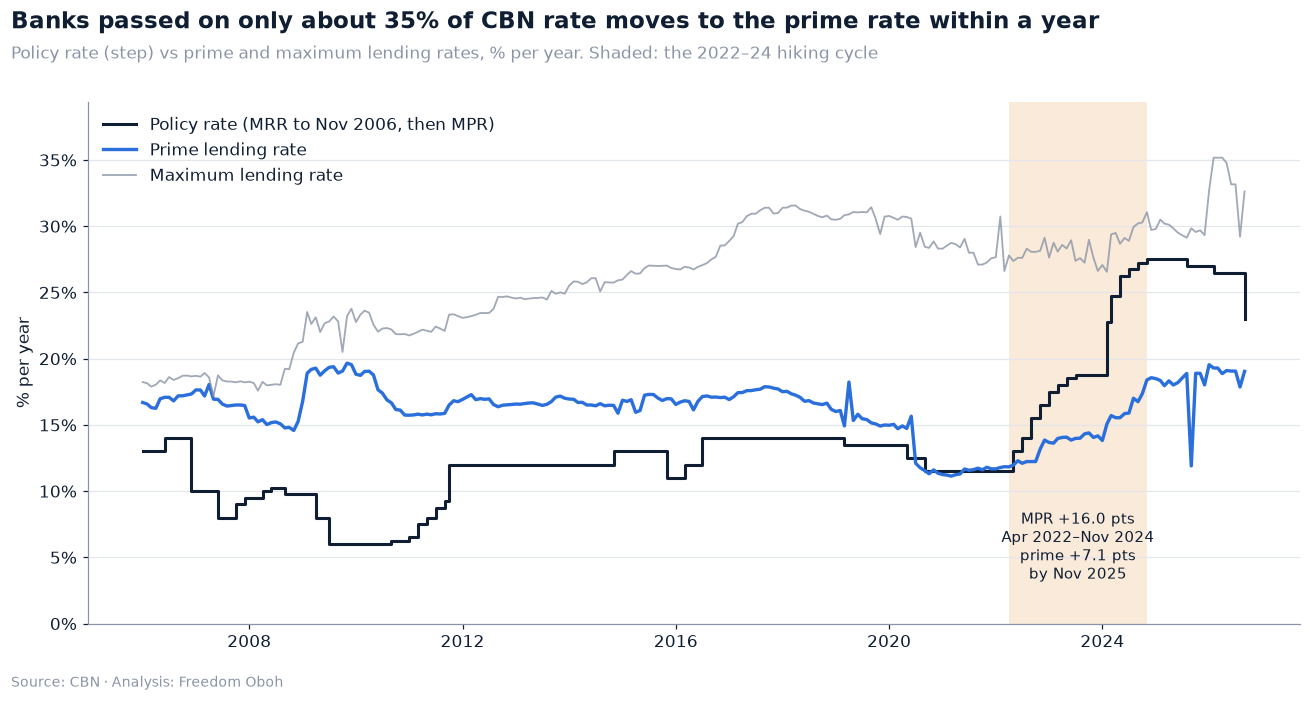

In [21]:
fig, ax = plt.subplots(figsize=(12, 6.3))
ax.axvspan(cycle_start, cycle_end, color=style.PALE_ORANGE, alpha=0.6, linewidth=0)
ax.step(p.index, p["policy_rate"], where="post", color=style.NAVY, linewidth=2,
        label="Policy rate (MRR to Nov 2006, then MPR)")
ax.plot(p.index, p["primeLending"], color=style.BLUE, linewidth=2.2, label="Prime lending rate")
ax.plot(p.index, p["maxLending"], color=style.GREY, linewidth=1.2, alpha=0.8, label="Maximum lending rate")

ax.text(cycle_start + (cycle_end - cycle_start) / 2, 3,
        f"MPR +{X:.1f} pts\n{cycle_start:%b %Y}–{cycle_end:%b %Y}\nprime +{prime_move_after:.1f} pts\nby {after:%b %Y}",
        ha="center", va="bottom", fontsize=10, color=style.NAVY)

ax.set_ylim(0, p["maxLending"].max() * 1.12)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("% per year")
ax.legend(loc="upper left")
style.titles(fig, ax,
             f"Banks passed on only about {Y:.0%} of CBN rate moves to the prime rate within a year",
             "Policy rate (step) vs prime and maximum lending rates, % per year. Shaded: the 2022–24 hiking cycle")
style.finish(fig, "03_mpr_vs_prime.png")
plt.show()

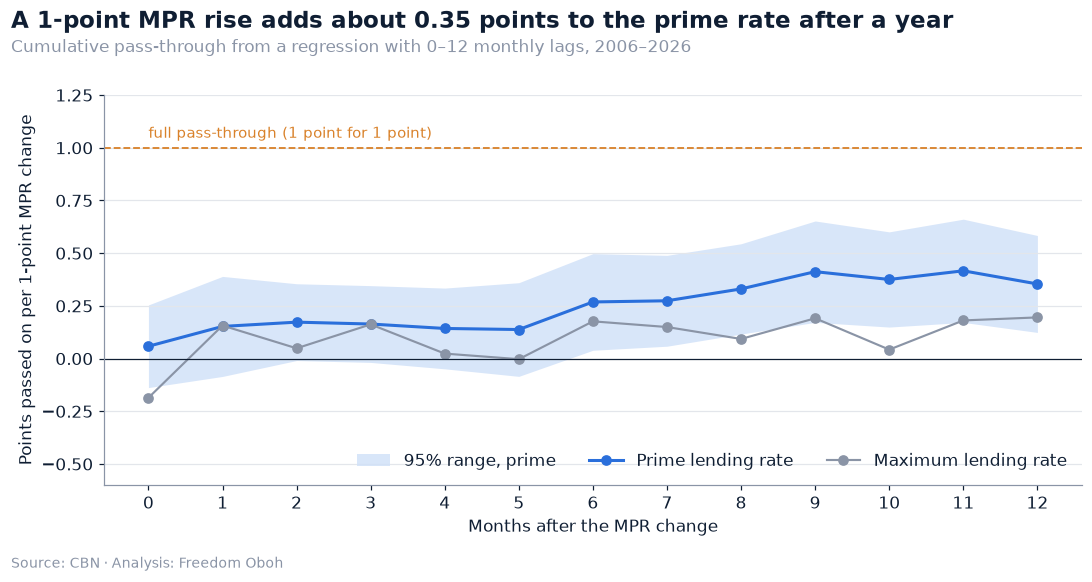

In [22]:
fig, ax = plt.subplots(figsize=(10, 5.2))
k = prime_pt.index
ax.fill_between(k, prime_pt["low"], prime_pt["high"], color=style.PALE_BLUE, alpha=0.8, linewidth=0,
                label="95% range, prime")
ax.plot(k, prime_pt["cumulative"], color=style.BLUE, marker="o", linewidth=2, label="Prime lending rate")
ax.plot(k, max_pt["cumulative"], color=style.GREY, marker="o", linewidth=1.4, label="Maximum lending rate")
ax.axhline(1, color=style.ORANGE, linestyle="--", linewidth=1.2)
ax.text(0, 1.03, "full pass-through (1 point for 1 point)", color=style.ORANGE, fontsize=10, va="bottom")
ax.axhline(0, color=style.NAVY, linewidth=0.8)
ax.set_xticks(list(k))
ax.set_xlabel("Months after the MPR change")
ax.set_ylabel("Points passed on per 1-point MPR change")
ax.set_ylim(-0.6, 1.25)
ax.legend(loc="lower right", ncols=3)
style.titles(fig, ax, f"A 1-point MPR rise adds about {Y:.2f} points to the prime rate after a year",
             "Cumulative pass-through from a regression with 0–12 monthly lags, 2006–2026")
style.finish(fig, "03b_pass_through.png")
plt.show()

In [23]:
print(f"In the last big cycle, the CBN raised its rate by {X:.1f} points ({cycle_start:%b %Y} to {cycle_end:%b %Y}).")
print(f"Twelve months after the last rise, the prime rate was up {prime_move_after:.1f} points and the maximum rate "
      f"{max_move_after:.1f} points.")
print(f"Across all 20 years, banks passed on about {Y:.2f} of each point to the prime rate, "
      f"with half of that arriving within about {Z} months.")

In the last big cycle, the CBN raised its rate by 16.0 points (Apr 2022 to Nov 2024).
Twelve months after the last rise, the prime rate was up 7.1 points and the maximum rate 1.9 points.
Across all 20 years, banks passed on about 0.35 of each point to the prime rate, with half of that arriving within about 6 months.


**What this means for Tunde and Amaka.** The CBN's lever does reach the street, but only partly and slowly. For big companies at the prime rate, about a third of a rate rise shows up within a year. For the maximum rate, the one closer to Amaka, the link is too noisy to measure with confidence. Her loan price seems to depend more on how risky the bank thinks she is than on what the CBN does. So when the CBN cuts its rate, Amaka shouldn't expect a cheaper loan soon.

> **Under the hood: method and limits.**
> - I use month-on-month **changes**, not levels, so the long upward drift in the maximum rate doesn't fake a connection.
> - The Dec 2006 drop from 14% (MRR) to 10% (MPR) is a change of instrument, so I left that month's change out (trap 1).
> - All three series are complete in the feed, and no filled values are used (trap 4).
> - Standard errors are Newey–West (HAC, 6 lags), which allow for runs of similar months.
> - The R² is very low. Most month-to-month movement in lending rates has nothing to do with the MPR: bank funding costs, the CRR (cash reserve requirement), T-bill yields and risk all matter too, and none of them are in this model.
> - I don't test whether rises and cuts pass through differently.
> - This is an average over 20 years. The pass-through in any single cycle can be larger or smaller.
> - **Correlation is not proof of cause.**

---
## Chapter 4: The queue. Who gets the credit?

**When Nigerian banks lend, who gets the money: government, or businesses and people?**

The CBN splits **net domestic credit** (all the credit the banking system gives inside Nigeria) into two parts:

- **Credit to government**: loans to government plus government securities the banks hold, *minus* government's deposits in the system.
- **Credit to the private sector**: loans to companies, small businesses and households, Amaka and Tunde included.

The CBN reports these in nominal naira. Because prices rose about 15× since 2006, I convert everything to **real naira at Sep 2026 prices**, using the price index from my savings project.

I expected government's share to grow. I didn't expect government to have been a *lender*, on net, for most of 2006–2014.

In [24]:
cr = p[["creditToPrivateSector", "creditToGovernment", "netDomesticCredit"]].copy()
check = (cr["netDomesticCredit"] - cr["creditToPrivateSector"] - cr["creditToGovernment"]).abs().max()
print(f"Net domestic credit = private + government (largest difference: ₦{check:.1f} million, rounding)")

# Real naira at the latest month's prices
to_latest_prices = p["price_index"].iloc[-1] / p["price_index"]
real_cr = cr.mul(to_latest_prices, axis=0) / 1e6   # ₦ trillion, Sep 2026 prices
real_cr.columns = ["private", "government", "total"]

gov_neg = cr["creditToGovernment"] < 0
print(f"Government credit negative in {gov_neg.sum()} months, between {cr.index[gov_neg].min():%b %Y} and {cr.index[gov_neg].max():%b %Y}.")

Net domestic credit = private + government (largest difference: ₦0.1 million, rounding)
Government credit negative in 93 months, between Jul 2006 and Jun 2014.


> **Under the hood: why credit to government is negative (trap 2).** From mid-2006 to June 2014, credit to government is negative in most months. This is not an error, and I don't drop or clip it. The CBN measures government credit *net* of government deposits. In those years, oil revenue meant government kept more money in the banking system, including at the CBN, than it borrowed from it. On net, government was a **lender** to the system. From mid-2014, as oil revenue fell and borrowing grew, it became a net borrower and has stayed one.

In [25]:
latest_real = real_cr.iloc[-1]
first_real = real_cr.iloc[0]
peak_month = real_cr["private"].idxmax()
peak = real_cr["private"].max()
nominal_multiple = cr["creditToPrivateSector"].iloc[-1] / cr["creditToPrivateSector"].iloc[0]
price_multiple = p["price_index"].iloc[-1] / p["price_index"].iloc[0]

print(f"Credit to the private sector, nominal: ₦{cr['creditToPrivateSector'].iloc[0]/1e6:.2f}tn -> "
      f"₦{cr['creditToPrivateSector'].iloc[-1]/1e6:.2f}tn ({nominal_multiple:.0f}x). Prices: {price_multiple:.1f}x.")
print(f"In Sep 2026 prices: ₦{first_real['private']:.1f}tn ({FIRST:%b %Y}) -> peak ₦{peak:.1f}tn ({peak_month:%b %Y}) "
      f"-> ₦{latest_real['private']:.1f}tn ({LAST:%b %Y}).")
print(f"Real private credit is {1 - latest_real['private'] / peak:.0%} below its peak "
      f"(the peak month is one of the sharp one-month jumps listed below, so treat it with care).")
back_to = real_cr["private"][real_cr["private"] >= latest_real["private"]].index[0]
print(f"A sturdier comparison: private credit first reached today's real level in {back_to:%b %Y}.")
print(f"Credit to government in Sep 2026 prices: ₦{first_real['government']:.1f}tn -> ₦{latest_real['government']:.1f}tn.")

Credit to the private sector, nominal: ₦1.98tn -> ₦83.93tn (42x). Prices: 15.5x.
In Sep 2026 prices: ₦30.7tn (Jan 2006) -> peak ₦142.0tn (Feb 2024) -> ₦83.9tn (Sep 2026).
Real private credit is 41% below its peak (the peak month is one of the sharp one-month jumps listed below, so treat it with care).
A sturdier comparison: private credit first reached today's real level in Apr 2008.
Credit to government in Sep 2026 prices: ₦6.5tn -> ₦39.4tn.


In [26]:
share = cr["creditToGovernment"] / cr["netDomesticCredit"] * 100
# Only meaningful when government is a net BORROWER; when it's negative, the "share" swings wildly
share_shown = share.where(cr["creditToGovernment"] > 0)
sh_first, sh_last = share.iloc[0], share.iloc[-1]
since = cr.index[(~gov_neg) & (cr.index > cr.index[gov_neg].max())][0]
after_2014 = share[since:]
print(f"Government's share of net domestic credit: {sh_first:.1f}% in {FIRST:%b %Y}, {sh_last:.1f}% in {LAST:%b %Y}.")
print(f"Since government became a net borrower again ({since:%b %Y}): average {after_2014.mean():.1f}%, "
      f"high {after_2014.max():.1f}% ({after_2014.idxmax():%b %Y}).")
pd.DataFrame({"government share (%)": share.resample("YS").last().round(1),
              "private share (%)": (100 - share).resample("YS").last().round(1)}).T.set_axis(
    share.resample("YS").last().index.year, axis=1)

Government's share of net domestic credit: 17.4% in Jan 2006, 31.9% in Sep 2026.
Since government became a net borrower again (Jul 2014): average 22.7%, high 41.3% (Apr 2023).


month,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
government share (%),-271.2,-88.1,-62.8,-30.0,-15.7,-7.8,-19.3,-11.4,6.0,13.4,...,14.0,17.6,26.2,27.8,28.4,37.1,34.9,25.8,31.1,31.9
private share (%),371.2,188.1,162.8,130.0,115.7,107.8,119.3,111.4,94.0,86.6,...,86.0,82.4,73.8,72.2,71.6,62.9,65.1,74.2,68.9,68.1


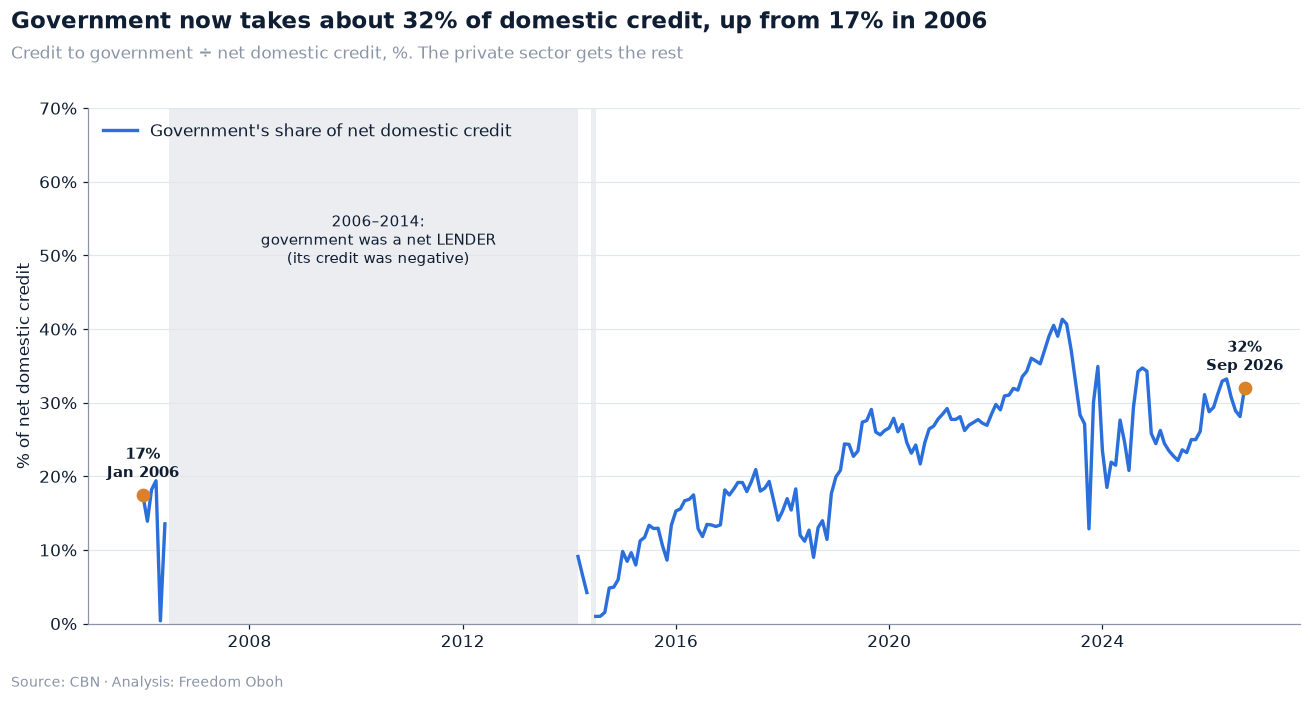

In [27]:
fig, ax = plt.subplots(figsize=(12, 6.3))
x = cr.index
# Shade the years when government was a net lender
runs = (gov_neg != gov_neg.shift()).cumsum()
for _, g in gov_neg[gov_neg].groupby(runs[gov_neg]):
    ax.axvspan(g.index[0], g.index[-1] + pd.DateOffset(months=1), color=style.LIGHT_GREY, alpha=0.7, linewidth=0)
ax.text(pd.Timestamp("2010-06-01"), 52, "2006–2014:\ngovernment was a net LENDER\n(its credit was negative)",
        ha="center", va="center", fontsize=10, color=style.NAVY)

ax.plot(x, share_shown.interpolate(limit_area="inside").where(~gov_neg), color=style.BLUE, linewidth=2.2,
        label="Government's share of net domestic credit")
for when, val in [(FIRST, sh_first), (LAST, sh_last)]:
    ax.plot(when, val, "o", color=style.ORANGE, markersize=8, zorder=3)
    ax.annotate(f"{val:.0f}%\n{when:%b %Y}", xy=(when, val), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=10, color=style.NAVY, fontweight="bold")

ax.set_ylim(0, 70)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("% of net domestic credit")
ax.legend(loc="upper left")
style.titles(fig, ax,
             f"Government now takes about {sh_last:.0f}% of domestic credit, up from {sh_first:.0f}% in {FIRST:%Y}",
             "Credit to government ÷ net domestic credit, %. The private sector gets the rest")
style.finish(fig, "04_government_share.png")
plt.show()

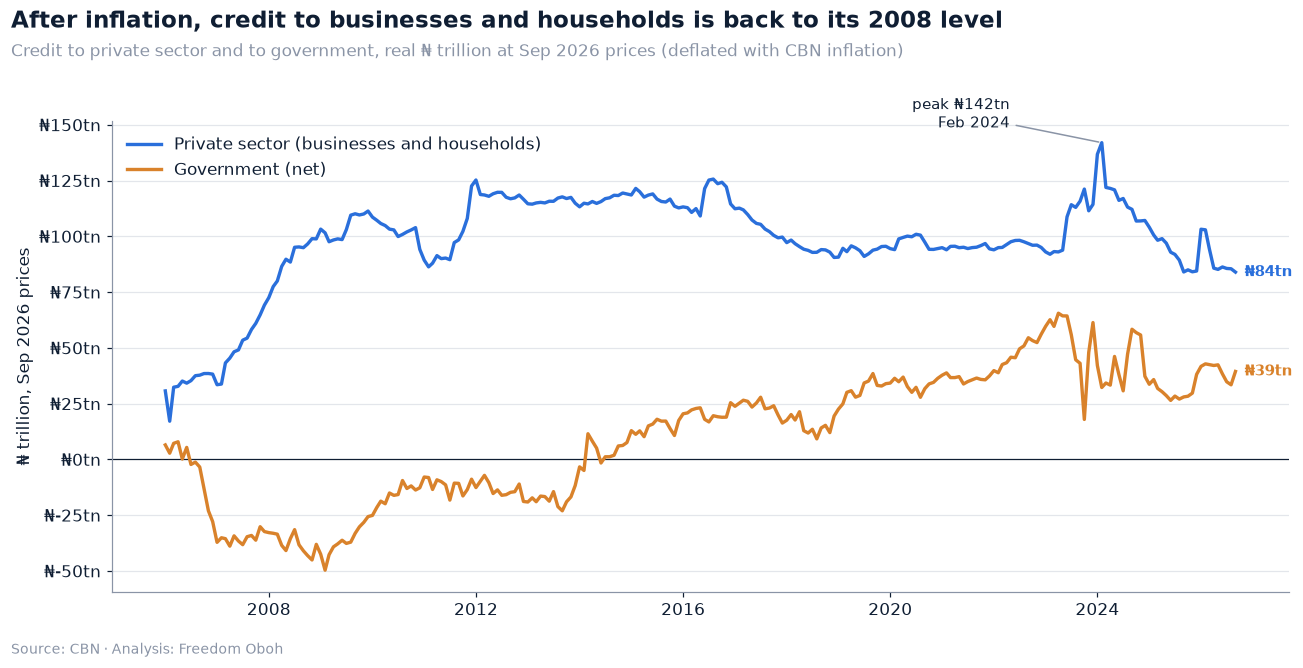

In [28]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_cr = real_cr.interpolate(limit_area="inside")  # Mar 2026 filled for the chart only (trap 4)
ax.axhline(0, color=style.NAVY, linewidth=0.8)
ax.plot(plot_cr.index, plot_cr["private"], color=style.BLUE, linewidth=2.2, label="Private sector (businesses and households)")
ax.plot(plot_cr.index, plot_cr["government"], color=style.ORANGE, linewidth=2.2, label="Government (net)")
ax.annotate(f"peak ₦{peak:.0f}tn\n{peak_month:%b %Y}", xy=(peak_month, peak), xytext=(-60, 10),
            textcoords="offset points", ha="right", fontsize=10, color=style.NAVY,
            arrowprops={"arrowstyle": "-", "color": style.GREY})
ax.annotate(f"₦{latest_real['private']:.0f}tn", xy=(LAST, latest_real["private"]), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=10, color=style.BLUE, fontweight="bold")
ax.annotate(f"₦{latest_real['government']:.0f}tn", xy=(LAST, latest_real["government"]), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=10, color=style.ORANGE, fontweight="bold")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"₦{v:.0f}tn"))
ax.set_ylabel("₦ trillion, Sep 2026 prices")
ax.legend(loc="upper left")
style.titles(fig, ax,
             f"After inflation, credit to businesses and households is back to its {back_to:%Y} level",
             "Credit to private sector and to government, real ₦ trillion at Sep 2026 prices (deflated with CBN inflation)")
style.finish(fig, "04b_real_credit.png")
plt.show()

In [29]:
jumps = cr["creditToPrivateSector"].pct_change(fill_method=None) * 100
big = jumps[jumps.abs() > 10].round(1)
print("Months where nominal private credit moved more than 10% in one month:")
print(big.to_string())

Months where nominal private credit moved more than 10% in one month:
month
2006-02-01   -43.8
2006-03-01    90.9
2007-01-01   -11.9
2007-03-01    28.6
2011-12-01    14.4
2016-06-01    12.7
2023-06-01    17.9
2024-01-01    22.3
2024-03-01   -12.1
2026-01-01    23.6


**What this means for Tunde and Amaka.** Out of every ₦100 of net credit the banking system gives inside Nigeria, about ₦30 now goes to government, against under ₦20 in 2006. And once inflation is taken out, the private sector's slice has *shrunk*: in real terms it is back to where it was in 2008, even though Nigeria has many more people and businesses now. The queue Amaka is standing in got longer and the pot got smaller.

Two outside figures (context only, not modelled here) show how short the private queue already was:
- Private sector credit was only about **17% of GDP in 2025**, **SMEs get about 1% of bank credit**, and about **55% of credit is shorter than one year** (CPPE policy brief, reported by [Nairametrics, 29 Mar 2026](https://nairametrics.com/2026/03/29/cppe-flags-weak-credit-allocation-despite-bank-recapitalisation-in-nigeria/)).
- "**Fewer than one in twenty MSMEs** have access to bank credit" ([World Bank press release, 22 Dec 2025](https://www.worldbank.org/en/news/press-release/2025/12/22/world-bank-approves-500-million-to-expand-finance-for-small-businesses-in-nigeria)).

> **Under the hood: nominal vs real (trap 3).**
> - The CBN reports credit in nominal ₦ millions. Every growth figure in this chapter is in real naira at Sep 2026 prices, deflated with my chained price index. That index is approximate: it is built from year-on-year inflation rates, and the CPI was rebased in Jan 2025.
> - The money and credit feed has no record for Mar 2026. The chart draws a straight line across that month, and no number in the text uses it.
> - Some single months jump sharply, for example Jan 2024 and Jan–Feb 2026 (table above). One possible reason is dollar loans being revalued when the naira moves, but this data can't confirm it, so I report the jumps as they are.
> - The "share" is government's net credit divided by net domestic credit. It is not shown for months when government credit is negative, because a share of a negative number has no plain meaning.

---
## Chapter 5: Why lend to Amaka when government pays well?

**If you were a bank, would you lend to a provisions shop or to the Federal Government?**

A **Treasury bill (T-bill)** is a short loan to the Federal Government, usually for 91 days to a year. A government that borrows in its own currency is very unlikely to fail to pay you back in naira, so a T-bill is about the safest thing a Nigerian bank can buy.

Lending to a company at the **prime rate** carries more risk: the company can fail. Lending to Amaka carries more still.

So a bank compares the two. If T-bills pay almost as much as a loan to a good company, with less risk and no paperwork, why lend to Amaka at all? Economists call this **crowding out**: when government borrows a lot and pays well for it, it can pull money away from lending to businesses and households. In plain words, government gets to the front of the queue because the bank finds it the easier customer.

That's the theory. Here's what the data shows. I'm not blaming any government or party: governments borrow for many reasons, and the CBN also uses T-bill and other rates to manage inflation.

In [30]:
tb = p["treasuryBill"]                      # unfilled: Dec 2017 and Dec 2018 stay missing
spread = p["primeLending"] - tb             # what a bank earns extra by lending to a top company
tb_beats_prime = spread <= 0

print(f"T-bill rate, {LAST:%b %Y}: {tb.iloc[-1]:.2f}%.  Prime lending rate: {p['primeLending'].iloc[-1]:.2f}%.")
print(f"Extra a bank earned lending at prime instead of buying T-bills: average {spread.mean():.1f} points, "
      f"{spread.iloc[-1]:.1f} in {LAST:%b %Y}.")
print(f"Months when the T-bill paid as much as or MORE than the prime rate: {tb_beats_prime.sum()} -> "
      f"{', '.join(p.index[tb_beats_prime].strftime('%b %Y'))}")

T-bill rate, Sep 2026: 16.24%.  Prime lending rate: 19.04%.
Extra a bank earned lending at prime instead of buying T-bills: average 7.2 points, 2.8 in Sep 2026.
Months when the T-bill paid as much as or MORE than the prime rate: 11 -> Feb 2024, Mar 2024, Apr 2024, May 2024, Jun 2024, Jul 2024, Aug 2024, Sep 2024, Apr 2025, May 2025, Sep 2025


### Do high T-bill rates come before slower private credit growth?

I measure **private credit growth** as the 12-month change in credit to the private sector **in real naira** (deflated with the price index), so inflation doesn't make credit look like it's growing when it isn't (trap 3). Then I check the correlation between the T-bill rate *today* and credit growth *0 to 12 months later*.

If crowding out is at work, I'd expect a **negative** correlation: high T-bill rates now, weaker credit growth later.

In [31]:
real_private = p["creditToPrivateSector"] / p["price_index"]
credit_growth = real_private.pct_change(12, fill_method=None) * 100   # no filling: Mar 2026 stays missing

def lag_corr(x, y, lags=range(13), start=None):
    x, y = (x[start:], y[start:]) if start else (x, y)
    return pd.Series([x.corr(y.shift(-k)) for k in lags], index=pd.Index(lags, name="months later"))

crowd = pd.DataFrame({
    "T-bill vs credit growth, 2006–2026": lag_corr(tb, credit_growth),
    "same, from 2010 (leaves out the 2006–08 credit boom)": lag_corr(tb, credit_growth, start="2010-01-01"),
})
crowd.round(2).T

months later,0,1,2,3,4,5,6,7,8,9,10,11,12
"T-bill vs credit growth, 2006–2026",-0.13,-0.15,-0.16,-0.18,-0.20,-0.22,-0.24,-0.24,-0.24,-0.24,-0.24,-0.24,-0.22
"same, from 2010 (leaves out the 2006–08 credit boom)",-0.07,-0.11,-0.13,-0.17,-0.23,-0.26,-0.29,-0.31,-0.32,-0.31,-0.33,-0.35,-0.35


In [32]:
best_lag = crowd.iloc[:, 0].idxmin()
best_r = crowd.iloc[:, 0].min()
r_2010 = crowd.iloc[:, 1].loc[best_lag]
print(f"Strongest (most negative) link: T-bill rate vs real credit growth {best_lag} months later, r = {best_r:.2f}.")
print(f"From 2010 only, at the same lag: r = {r_2010:.2f}.")
print(f"An r of {best_r:.2f} means the T-bill rate lines up with about {best_r**2:.0%} of the ups and downs in credit growth.")

Strongest (most negative) link: T-bill rate vs real credit growth 8 months later, r = -0.24.
From 2010 only, at the same lag: r = -0.32.
An r of -0.24 means the T-bill rate lines up with about 6% of the ups and downs in credit growth.


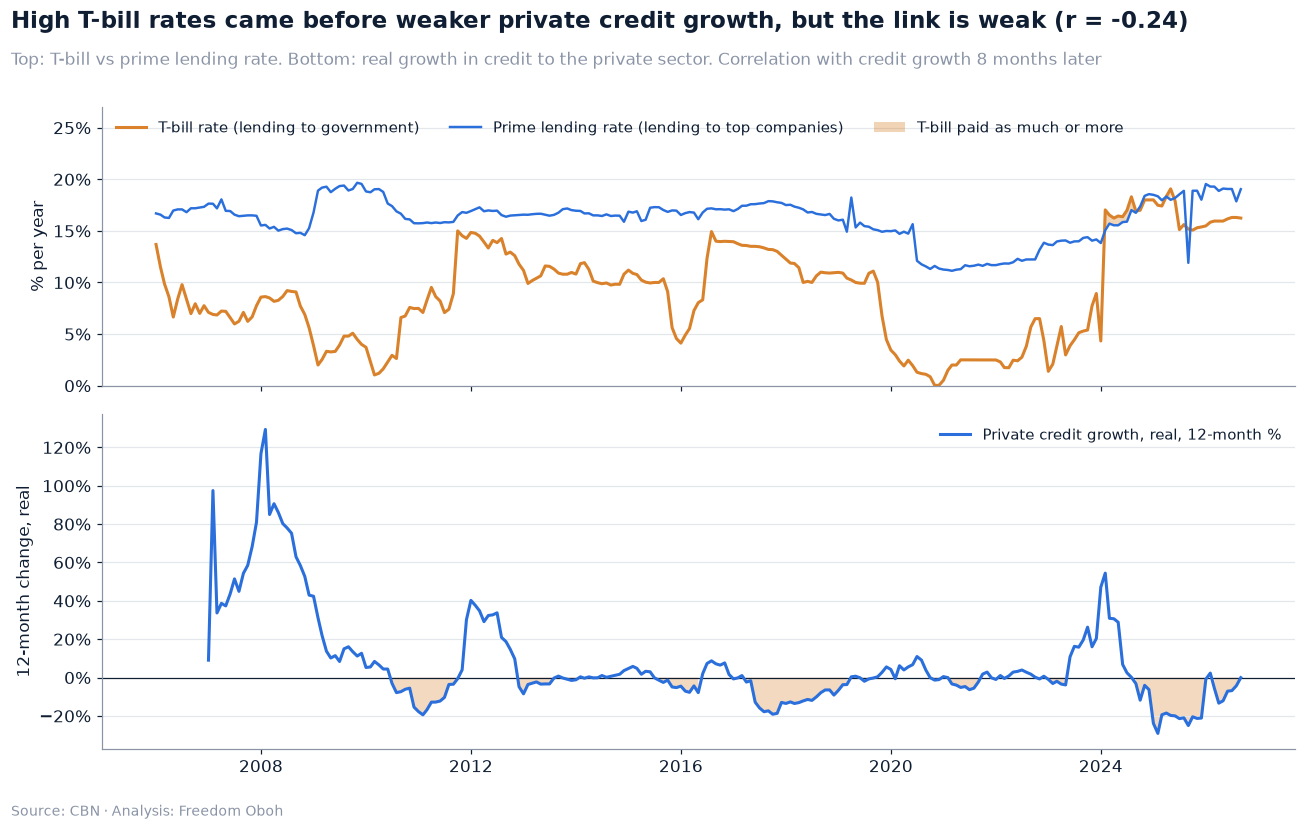

In [33]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
tb_chart = p["treasuryBill_filled"]  # gaps filled for the chart only
ax1.plot(p.index, tb_chart, color=style.ORANGE, linewidth=2, label="T-bill rate (lending to government)")
ax1.plot(p.index, p["primeLending"], color=style.BLUE, linewidth=1.6, label="Prime lending rate (lending to top companies)")
ax1.fill_between(p.index, tb_chart, p["primeLending"], where=tb_beats_prime.fillna(False), color=style.ORANGE,
                 alpha=0.35, linewidth=0, label="T-bill paid as much or more")
ax1.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax1.set_ylabel("% per year")
ax1.set_ylim(0, 27)
ax1.legend(loc="upper left", fontsize=10, ncols=3)

g_chart = credit_growth.interpolate(limit_area="inside")
ax2.axhline(0, color=style.NAVY, linewidth=0.8)
ax2.fill_between(p.index, g_chart, 0, where=g_chart < 0, color=style.ORANGE, alpha=0.3, linewidth=0)
ax2.plot(p.index, g_chart, color=style.BLUE, linewidth=2, label="Private credit growth, real, 12-month %")
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax2.set_ylabel("12-month change, real")
ax2.legend(loc="upper right", fontsize=10)

style.titles(fig, ax1,
             f"High T-bill rates came before weaker private credit growth, but the link is weak (r = {best_r:.2f})",
             f"Top: T-bill vs prime lending rate. Bottom: real growth in credit to the private sector. Correlation with credit growth {best_lag} months later")
style.finish(fig, "05_tbill_vs_private_credit.png", top=0.89)
plt.show()

In [34]:
print(f"In {LAST:%B %Y}, a bank could earn {tb.iloc[-1]:.1f}% lending to government through T-bills,")
print(f"or about {p['primeLending'].iloc[-1]:.1f}% lending to a top company: only {spread.iloc[-1]:.1f} points more, for far more risk.")
print(f"Lending to Amaka at near the maximum rate ({p['maxLending'].iloc[-1]:.1f}%) pays more, but she is the riskiest of the three.")

In September 2026, a bank could earn 16.2% lending to government through T-bills,
or about 19.0% lending to a top company: only 2.8 points more, for far more risk.
Lending to Amaka at near the maximum rate (32.6%) pays more, but she is the riskiest of the three.


**What this means for Tunde and Amaka.** For most of the last 20 years, lending to a top company paid a bank several points more than a T-bill. But in 2024 and 2025 the gap closed completely in several months: the government paid the same or more, with almost no risk. In those months, a bank had little reason to take on the work and risk of lending to Amaka's shop. The data shows the expected pattern, with credit growth weaker after high T-bill rates, but the link is weak. **Correlation is not proof.** Credit growth also depends on the economy, bank capital, CBN rules on how much banks must lend or hold, the exchange rate, and whether businesses want to borrow at all.

> **Under the hood: crowding out, carefully.**
> - Credit growth is measured in real terms (trap 3).
> - The T-bill rate is missing for Dec 2017 and Dec 2018, and the credit data for Mar 2026. None of these months are filled for the correlations; pandas just skips them. They are filled only for drawing the chart (trap 4).
> - The 12-month growth figures overlap from month to month, so neighbouring months aren't independent. I report correlations, not p-values, because the usual significance tests would overstate how sure we can be.
> - Leaving out 2006–2008, when credit grew very fast from a low base, checks that one early boom isn't driving the result.
> - The "T-bill" here is the CBN's monthly average Treasury bill rate. Actual auction rates for different tenors vary.

---
## Chapter 6: The loan app on Tunde's phone

**The bank says "bring collateral and wait two weeks". The app says "approved in five minutes". What does the fast option cost?**

Digital lenders (loan apps) are the new-age option. You need a phone, a BVN and a bank account. No collateral and no guarantor. The money can land in minutes. But they price their loans **per month**, while banks quote **per year**, so the two are hard to compare at a glance.

There is no official dataset of loan app rates, so I built a small one by hand: `data/loan_offers.csv`. Every row has a source link and a date. Where I could, I checked the rate on the lender's own website or Google Play listing. Where neither gave a rate, I used a news report, labelled `news`. Every lender is on the FCCPC's register of digital lenders (checked 5 Nov 2026). These are **advertised rates**. The rate a real borrower is offered depends on their profile, and **I don't rank or recommend any lender**: this chapter compares price ranges, not brands.

In [35]:
offers = pd.read_csv(ROOT / "data" / "loan_offers.csv")
REPORTED = "advertised rates, as reported 25 Apr – 5 Nov 2026"
FCCPC_LIST = "FCCPC approvals of digital money lenders page (fccpc.gov.ng/approvals-of-dmls), viewed 5 Nov 2026"
from_lender = offers["source_type"].str.startswith("lender site")

print(f"{len(offers)} loan products from {offers['lender'].str.split(' ').str[0].nunique()} lenders "
      f"({from_lender.sum()} checked on lender sites or Google Play listings, {(~from_lender).sum()} from news reports)")
print(f"Register checked: {FCCPC_LIST}")
offers[["lender", "product_type", "min_monthly_rate", "max_monthly_rate", "max_amount", "min_tenor_days",
        "max_tenor_days", "source_type", "date_accessed"]]

10 loan products from 9 lenders (6 checked on lender sites or Google Play listings, 4 from news reports)
Register checked: FCCPC approvals of digital money lenders page (fccpc.gov.ng/approvals-of-dmls), viewed 5 Nov 2026


,lender,product_type,min_monthly_rate,max_monthly_rate,max_amount,min_tenor_days,max_tenor_days,source_type,date_accessed
0,Airmoni,quick loan,1.50,1.50,"₦500,000",91.0,365.0,lender site (Google Play),2026-11-05
1,Branch,quick loan,2.80,19.00,"₦1,000,000",28.0,364.0,lender site,2026-11-05
2,Carbon (personal loan),quick loan,4.50,30.00,"₦1,000,000",61.0,365.0,lender site,2026-11-05
3,Carbon (business working capital),business loan,3.99,NaN,"₦9,500,000",30.0,180.0,lender site,2026-11-05
4,EaseMoni,quick loan,5.00,10.00,"₦2,000,000",NaN,NaN,news,2026-11-05
5,FairMoney,quick loan,2.00,38.00,"₦5,000,000",NaN,NaN,lender site,2026-11-05
6,LetsGo (Letshego MFB),payroll loan,2.00,2.00,NaN,90.0,2520.0,lender site (Google Play),2026-11-05
7,Okash,quick loan,3.00,15.00,NaN,NaN,NaN,news,2026-11-05
8,QuickCheck,quick loan,2.00,5.00,"₦50,000",NaN,NaN,news,2026-11-05
9,Renmoney,quick loan,2.12,2.65,"₦1,000,000",NaN,NaN,news,2026-11-05


### Step 1: turn monthly rates into yearly ones

Two ways to do it:
- **Simple annual rate** = monthly rate × 12. This is how lenders often quote an "APR" (annual percentage rate: the yearly cost of a loan).
- **Effective annual rate** = (1 + monthly rate)¹² − 1. This is what the monthly rate adds up to if interest builds on interest for a full year.

In [36]:
annual = offers[["lender", "min_monthly_rate", "max_monthly_rate"]].copy()
for end in ["min", "max"]:
    annual[f"{end}: simple yearly %"] = loan_math.simple_annual(annual[f"{end}_monthly_rate"]).round(1)
    annual[f"{end}: effective yearly %"] = loan_math.effective_annual(annual[f"{end}_monthly_rate"]).round(0)
print(f"Bank rates for comparison ({LAST:%b %Y}): prime {p['primeLending'].iloc[-1]:.2f}% a year, "
      f"maximum {p['maxLending'].iloc[-1]:.2f}% a year.")
annual

Bank rates for comparison (Sep 2026): prime 19.04% a year, maximum 32.62% a year.


,lender,min_monthly_rate,max_monthly_rate,min: simple yearly %,min: effective yearly %,max: simple yearly %,max: effective yearly %
0,Airmoni,1.50,1.50,18.0,20.0,18.0,20.0
1,Branch,2.80,19.00,33.6,39.0,228.0,706.0
2,Carbon (personal loan),4.50,30.00,54.0,70.0,360.0,2230.0
3,Carbon (business working capital),3.99,NaN,47.9,60.0,NaN,NaN
4,EaseMoni,5.00,10.00,60.0,80.0,120.0,214.0
5,FairMoney,2.00,38.00,24.0,27.0,456.0,4670.0
6,LetsGo (Letshego MFB),2.00,2.00,24.0,27.0,24.0,27.0
7,Okash,3.00,15.00,36.0,43.0,180.0,435.0
8,QuickCheck,2.00,5.00,24.0,27.0,60.0,80.0
9,Renmoney,2.12,2.65,25.4,29.0,31.8,37.0


### Step 2: which apps fit each person's loan?

An advertised rate only matters if the product fits the loan. Tunde needs **1 month (30 days)** and Amaka needs **6 months (180 days)**. So for each of them I keep only products whose advertised tenor covers their loan. I leave out **payroll loans**, which need an employer arrangement, and for Tunde I also leave out **business loans**, since he isn't borrowing for a business. Products whose tenor isn't published stay in.

Then I sum up each person's products in three numbers:
- **Typical starting rate**: the median of the advertised *minimum* rates.
- **Typical mid rate**: the median of the mid-points of each advertised range (products that state both a minimum and a maximum).
- **Highest advertised**: the highest advertised maximum.

For the bank, I turn the CBN's yearly prime and maximum lending rates into monthly rates (÷ 12, as banks quote them).

In [37]:
TUNDE = dict(principal=100_000, months=1, days=30)
AMAKA = dict(principal=500_000, months=6, days=180)


def fits(row, days, allow_business):
    if row["product_type"] == "payroll loan":
        return False
    if row["product_type"] == "business loan" and not allow_business:
        return False
    if pd.isna(row["min_tenor_days"]) or pd.isna(row["max_tenor_days"]):
        return True  # tenor unknown: kept, and listed below
    return row["min_tenor_days"] <= days <= row["max_tenor_days"]


def tiers(products):
    both = products.dropna(subset=["min_monthly_rate", "max_monthly_rate"])
    return {
        "start": products["min_monthly_rate"].median(),
        "mid": ((both["min_monthly_rate"] + both["max_monthly_rate"]) / 2).median(),
        "high": products["max_monthly_rate"].max(),
    }


fit_tunde = offers.apply(fits, axis=1, days=TUNDE["days"], allow_business=False)
fit_amaka = offers.apply(fits, axis=1, days=AMAKA["days"], allow_business=True)
TIERS = {"Tunde": tiers(offers[fit_tunde]), "Amaka": tiers(offers[fit_amaka])}

fit_table = offers[["lender", "product_type", "min_monthly_rate", "min_tenor_days", "max_tenor_days"]].assign(
    **{"fits Tunde (30 days)": fit_tunde, "fits Amaka (180 days)": fit_amaka})
print(f"Products used for Tunde: {fit_tunde.sum()}.  For Amaka: {fit_amaka.sum()}.")
pd.DataFrame(TIERS).rename(index={"start": "typical starting rate", "mid": "typical mid rate",
                                  "high": "highest advertised"}).round(2)

Products used for Tunde: 6.  For Amaka: 9.


,Tunde,Amaka
typical starting rate,2.46,2.80
typical mid rate,8.25,8.25
highest advertised,38.00,38.00


In [38]:
unknown_tenor = offers.loc[offers["min_tenor_days"].isna(), "lender"].tolist()
not_for_tunde = offers[~fit_tunde].sort_values("min_monthly_rate")
cheap_not_1m = offers[(offers["min_monthly_rate"] < TIERS["Tunde"]["start"]) & (offers["min_tenor_days"] > TUNDE["days"])]
print(f"Tenor not published (kept in both): {', '.join(unknown_tenor)}")
print("Left out for Tunde:")
for _, r in not_for_tunde.iterrows():
    why = (r["product_type"] if r["product_type"] in ("payroll loan", "business loan")
           else f"tenor {r['min_tenor_days']:.0f}–{r['max_tenor_days']:.0f} days")
    print(f"  {r['lender']}: from {r['min_monthly_rate']}% a month ({why})")
cheap_names = " and ".join(cheap_not_1m["lender"].str.split(" ").str[0])
cheap_rates = ", ".join(f"{r['lender'].split(' ')[0]} from {r['min_monthly_rate']}%" for _, r in cheap_not_1m.iterrows())
print(f"\nAdvertised below Tunde's typical starting rate ({TIERS['Tunde']['start']:.2f}% a month) but with no 1-month loan: "
      f"{cheap_rates}. The cheapest advertised apps aren't open to someone in Tunde's position.")

Tenor not published (kept in both): EaseMoni, FairMoney, Okash, QuickCheck, Renmoney
Left out for Tunde:
  Airmoni: from 1.5% a month (tenor 91–365 days)
  LetsGo (Letshego MFB): from 2.0% a month (payroll loan)
  Carbon (business working capital): from 3.99% a month (business loan)
  Carbon (personal loan): from 4.5% a month (tenor 61–365 days)

Advertised below Tunde's typical starting rate (2.46% a month) but with no 1-month loan: Airmoni from 1.5%, LetsGo from 2.0%. The cheapest advertised apps aren't open to someone in Tunde's position.


### Step 3: what do Tunde and Amaka repay?

- **Tunde** borrows **₦100,000 for 1 month**.
- **Amaka** borrows **₦500,000 for 6 months**, repaid in equal monthly instalments.

To compare like with like, the main table uses **reducing balance** for everyone: interest is charged only on what is still owed. That's the cheapest way an app could charge, so the app figures below are, if anything, too kind to the apps. (Step 4 shows what happens with flat interest.)

In [39]:
BANK_PRIME_M = loan_math.annual_to_monthly(p["primeLending"].iloc[-1])
BANK_MAX_M = loan_math.annual_to_monthly(p["maxLending"].iloc[-1])
ROWS = ["Bank: prime rate", "Bank: maximum rate", "Loan app: typical starting rate",
        "Loan app: typical mid rate", "Loan app: highest advertised"]


def rates_for(who):
    t = TIERS[who]
    return pd.Series([BANK_PRIME_M, BANK_MAX_M, t["start"], t["mid"], t["high"]], index=ROWS)


rate_t, rate_a = rates_for("Tunde"), rates_for("Amaka")
repay = pd.DataFrame({
    "Tunde: monthly rate %": rate_t,
    "Tunde repays (₦100k, 1 month)": [loan_math.repayment(TUNDE["principal"], r, TUNDE["months"], "reducing") for r in rate_t],
    "Amaka: monthly rate %": rate_a,
    "Amaka repays (₦500k, 6 months)": [loan_math.repayment(AMAKA["principal"], r, AMAKA["months"], "reducing") for r in rate_a],
}, index=ROWS)
TUNDE_PAY, AMAKA_PAY = repay["Tunde repays (₦100k, 1 month)"], repay["Amaka repays (₦500k, 6 months)"]
repay.assign(**{
    "Tunde repays (₦100k, 1 month)": TUNDE_PAY.map(lambda v: f"₦{v:,.0f}"),
    "Amaka repays (₦500k, 6 months)": AMAKA_PAY.map(lambda v: f"₦{v:,.0f}"),
}).round(2)

,Tunde: monthly rate %,"Tunde repays (₦100k, 1 month)",Amaka: monthly rate %,"Amaka repays (₦500k, 6 months)"
Bank: prime rate,1.59,"₦101,587",1.59,"₦528,131"
Bank: maximum rate,2.72,"₦102,718",2.72,"₦548,634"
Loan app: typical starting rate,2.46,"₦102,460",2.80,"₦550,127"
Loan app: typical mid rate,8.25,"₦108,250",8.25,"₦653,876"
Loan app: highest advertised,38.00,"₦138,000",38.00,"₦1,332,999"


In [40]:
# Hand checks (CLAUDE.md section 9)
mid_t = TIERS["Tunde"]["mid"]
hand = 100_000 * (1 + mid_t / 100)
print(f"By hand: ₦100,000 × (1 + {mid_t}%) = ₦{hand:,.2f}.  Calculator: ₦{TUNDE_PAY['Loan app: typical mid rate']:,.2f}.  "
      f"Match: {abs(hand - TUNDE_PAY['Loan app: typical mid rate']) < 0.01}")
r = BANK_PRIME_M / 100
inst = 500_000 * r / (1 - (1 + r) ** -6)
print(f"By hand: Amaka's instalment at {BANK_PRIME_M:.3f}% a month = ₦{inst:,.2f}; × 6 = ₦{inst * 6:,.2f}.  "
      f"Calculator: ₦{AMAKA_PAY['Bank: prime rate']:,.2f}")

By hand: ₦100,000 × (1 + 8.25%) = ₦108,250.00.  Calculator: ₦108,250.00.  Match: True
By hand: Amaka's instalment at 1.587% a month = ₦88,021.81; × 6 = ₦528,130.87.  Calculator: ₦528,130.87


In [41]:
# How close is a good app offer to a bank loan at the maximum rate? (monthly rates)
CLOSE = 0.5  # percentage points a month
app_vs_bank = {}
for who in ["Tunde", "Amaka"]:
    gap_pts = TIERS[who]["start"] - BANK_MAX_M
    app_vs_bank[who] = gap_pts
    print(f"{who}: typical starting app rate {TIERS[who]['start']:.2f}% a month vs bank maximum {BANK_MAX_M:.2f}% "
          f"-> difference {gap_pts:+.2f} points a month")
close = all(abs(v) <= CLOSE for v in app_vs_bank.values())
if close:
    APP_VS_BANK_SENTENCE = (f"A good app offer can cost about the same as a bank loan at the maximum rate: a typical starting app rate of "
                            f"{TIERS['Tunde']['start']:.2f}% a month for Tunde and {TIERS['Amaka']['start']:.2f}% for Amaka, against "
                            f"{BANK_MAX_M:.2f}% at the bank. The real danger is the highest advertised rates and what happens after the due date.")
else:
    APP_VS_BANK_SENTENCE = (f"Even a typical starting app rate ({TIERS['Tunde']['start']:.2f}% a month for Tunde, "
                            f"{TIERS['Amaka']['start']:.2f}% for Amaka) differs clearly from a bank loan at the maximum rate "
                            f"({BANK_MAX_M:.2f}% a month).")
print("\n" + APP_VS_BANK_SENTENCE)

Tunde: typical starting app rate 2.46% a month vs bank maximum 2.72% -> difference -0.26 points a month
Amaka: typical starting app rate 2.80% a month vs bank maximum 2.72% -> difference +0.08 points a month

A good app offer can cost about the same as a bank loan at the maximum rate: a typical starting app rate of 2.46% a month for Tunde and 2.80% for Amaka, against 2.72% at the bank. The real danger is the highest advertised rates and what happens after the due date.


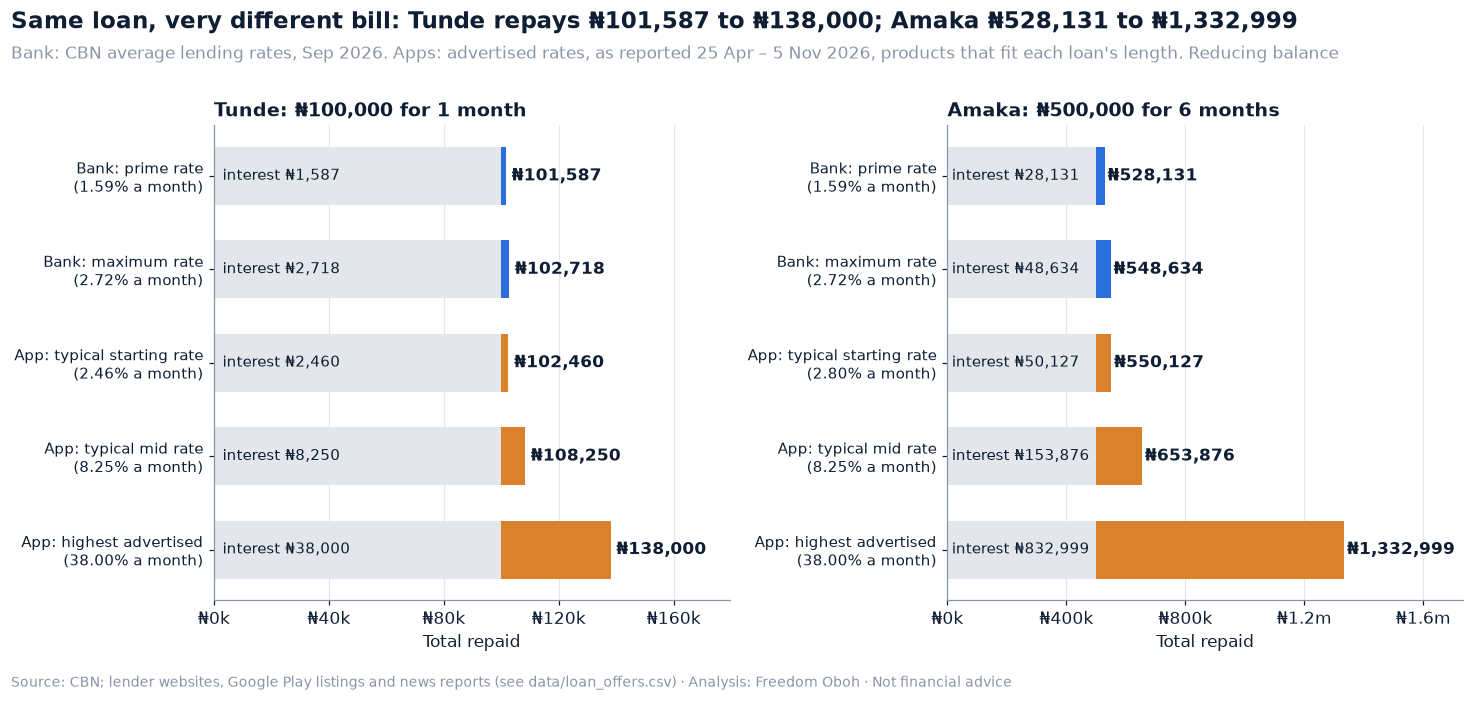

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.3))
colors = [style.BLUE, style.BLUE, style.ORANGE, style.ORANGE, style.ORANGE]
panels = [("Tunde: ₦100,000 for 1 month", TUNDE, TUNDE_PAY, rate_t),
          ("Amaka: ₦500,000 for 6 months", AMAKA, AMAKA_PAY, rate_a)]
for ax, (who, cfg, totals_s, rates_s) in zip(axes, panels):
    totals = totals_s.values
    interest = totals - cfg["principal"]
    y = np.arange(len(ROWS))[::-1]
    ax.barh(y, [cfg["principal"]] * len(y), color=style.LIGHT_GREY, height=0.62)
    ax.barh(y, interest, left=cfg["principal"], color=colors, height=0.62)
    for yi, tot, intr in zip(y, totals, interest):
        ax.text(tot + cfg["principal"] * 0.02, yi, f"₦{tot:,.0f}", va="center", fontsize=11,
                fontweight="bold", color=style.NAVY)
        ax.text(cfg["principal"] * 0.03, yi, f"interest ₦{intr:,.0f}", va="center", fontsize=9.5, color=style.NAVY)
    ax.set_xlim(0, totals.max() * 1.3)
    ax.set_title(who, loc="left", fontsize=12.5, fontweight="bold", color=style.NAVY)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(5))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda v, _: f"₦{v / 1e6:g}m" if v >= 1e6 else f"₦{v / 1000:,.0f}k"))
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color=style.LIGHT_GREY)
    ax.set_axisbelow(True)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{l.replace('Loan app: ', 'App: ')}\n({rates_s[l]:.2f}% a month)" for l in ROWS], fontsize=10)
    ax.set_xlabel("Total repaid")

t_bank, t_high = TUNDE_PAY.iloc[0], TUNDE_PAY.iloc[-1]
a_bank, a_high = AMAKA_PAY.iloc[0], AMAKA_PAY.iloc[-1]
style.titles(fig, axes[0],
             f"Same loan, very different bill: Tunde repays ₦{t_bank:,.0f} to ₦{t_high:,.0f}; Amaka ₦{a_bank:,.0f} to ₦{a_high:,.0f}",
             f"Bank: CBN average lending rates, {LAST:%b %Y}. Apps: {REPORTED}, products that fit each loan's length. Reducing balance")
style.finish(fig, "06_repayment.png",
             source="Source: CBN; lender websites, Google Play listings and news reports (see data/loan_offers.csv) · "
                    "Analysis: Freedom Oboh · Not financial advice")
plt.show()

### Step 4: flat rate vs reducing balance (trap 6)

Many apps charge **flat** interest: the monthly rate applies to the *full* amount you borrowed, every month, even after you've paid part of it back. Lenders' own examples show this. Carbon's website gives ₦1,000,000 for 12 months at 4.5% a month, total payable ₦1,540,000. FairMoney's Google Play listing gives ₦100,000 over 3 months with ₦30,000 interest (10% a month, flat).

For a one-month loan like Tunde's, flat and reducing give the same answer. For Amaka's six months, they don't.

In [43]:
carbon_example = loan_math.flat_total(1_000_000, 4.5, 12)
fairmoney_example = loan_math.flat_total(100_000, 10, 3)
print(f"Lender examples, flat: ₦1,000,000 at 4.5% for 12 months = ₦{carbon_example:,.0f}; "
      f"₦100,000 at 10% for 3 months = ₦{fairmoney_example:,.0f}")

a_start, a_mid = TIERS["Amaka"]["start"], TIERS["Amaka"]["mid"]
flat_vs = pd.DataFrame({
    "flat": [loan_math.flat_total(AMAKA["principal"], r, AMAKA["months"]) for r in [a_start, a_mid]],
    "reducing balance": [loan_math.reducing_total(AMAKA["principal"], r, AMAKA["months"]) for r in [a_start, a_mid]],
}, index=[f"Typical starting rate ({a_start}%)", f"Typical mid rate ({a_mid}%)"])
flat_vs["extra from flat"] = flat_vs["flat"] - flat_vs["reducing balance"]
flat_vs.round(0).map(lambda v: f"₦{v:,.0f}")

Lender examples, flat: ₦1,000,000 at 4.5% for 12 months = ₦1,540,000; ₦100,000 at 10% for 3 months = ₦130,000


,flat,reducing balance,extra from flat
Typical starting rate (2.8%),"₦584,000","₦550,127","₦33,873"
Typical mid rate (8.25%),"₦747,500","₦653,876","₦93,624"


In [44]:
mid_flat, mid_red = flat_vs.iloc[1]["flat"], flat_vs.iloc[1]["reducing balance"]
print(f"At Amaka's typical mid rate, flat interest costs ₦{mid_flat - mid_red:,.0f} more than reducing balance "
      f"(₦{mid_flat:,.0f} vs ₦{mid_red:,.0f}). Interest is {(mid_flat - 500_000) / (mid_red - 500_000) - 1:.0%} higher.")
t_int = TUNDE_PAY - 100_000
a_int = AMAKA_PAY - 500_000
print(f"\nTunde, 1 month: interest ₦{t_int.iloc[0]:,.0f} at the bank's prime rate, ₦{t_int.iloc[3]:,.0f} at the typical mid app rate, "
      f"₦{t_int.iloc[4]:,.0f} at the highest advertised.")
print(f"Amaka, 6 months: interest ₦{a_int.iloc[0]:,.0f} at the bank's prime rate; ₦{a_int.iloc[3]:,.0f} at the typical mid app rate "
      f"(reducing) or ₦{mid_flat - 500_000:,.0f} (flat).")

At Amaka's typical mid rate, flat interest costs ₦93,624 more than reducing balance (₦747,500 vs ₦653,876). Interest is 61% higher.

Tunde, 1 month: interest ₦1,587 at the bank's prime rate, ₦8,250 at the typical mid app rate, ₦38,000 at the highest advertised.
Amaka, 6 months: interest ₦28,131 at the bank's prime rate; ₦153,876 at the typical mid app rate (reducing) or ₦247,500 (flat).


### Why do apps charge so much more?

It's easy to call loan apps greedy. The fuller picture:

- **No collateral.** A bank can take your property if you don't pay. An app can't, so it prices in more losses.
- **High default risk.** Apps lend to people banks have turned away, often with little credit history. When many borrowers don't repay, the ones who do pay for them.
- **Cost of money.** Apps borrow to lend. Their own funding often costs more than the T-bill or prime rates from Chapters 1 and 5.
- **Short tenors, fixed costs.** Checking a customer, sending the money and collecting it costs about the same for ₦20,000 as for ₦2 million. On a small loan for a few weeks, that fixed cost is a large part of the price.

None of that makes the highest advertised rates cheap. It explains why the price is high, and why it's charged per month.

### What changed with regulation

In July 2025 the FCCPC (Federal Competition and Consumer Protection Commission) made the **[Digital, Electronic, Online, or Non-Traditional Consumer Lending Regulations, 2025](https://fccpc.gov.ng/wp-content/uploads/2025/08/DIGITAL-CONSUMER-LENDING-2025-LATEST.pdf)**:

- **Registration.** Digital lenders must register with and be approved by the FCCPC. By Oct 2025, 492 companies had registered ([Nairametrics, 23 Oct 2025](https://nairametrics.com/2025/10/23/fccpc-registered-loan-apps-surge-to-492-amid-n100-million-penalty-rule)).
- **Disclosure.** Interest rates, repayment terms and fees must be disclosed in plain language before you borrow, and lending rates must be shown clearly on the lender's website. While collecting this data, I found some lender websites still don't show a rate.
- **No contacts or photos.** Lenders must confirm their apps will not access a borrower's call logs, contacts or photo gallery. Using these to shame borrowers was the worst practice of the early loan-app years.
- **Penalties.** Fines up to ₦100 million or 1% of the previous year's turnover for companies, plus suspension, delisting, or disqualification of directors.
- **No rate cap.** The regulations say the FCCPC will monitor rates so they are not "exploitative", but they set **no maximum interest rate** ([Nairametrics, 21 Aug 2025](https://nairametrics.com/2025/08/21/fccpcs-new-rule-on-loan-app-interest-rates-unsettles-nigerias-digital-lenders/)).

In [45]:
display(Markdown(f'''**What this means for Tunde and Amaka.** {APP_VS_BANK_SENTENCE}

For Tunde's one-month emergency, the bank's rate is the cheapest on paper, but a bank is unlikely to give a salary earner ₦100,000 for one month in a hurry. The app will. And the cheapest advertised apps ({cheap_names}) don't offer a one-month loan at all, so the lowest rates in the file aren't open to him. For Amaka, six months is where it really bites: the length of the loan multiplies a monthly price, and flat interest multiplies it again. The practical lesson is general: **turn any monthly rate into a yearly one, and ask whether interest is flat or reducing, before you compare.**'''))

**What this means for Tunde and Amaka.** A good app offer can cost about the same as a bank loan at the maximum rate: a typical starting app rate of 2.46% a month for Tunde and 2.80% for Amaka, against 2.72% at the bank. The real danger is the highest advertised rates and what happens after the due date.

For Tunde's one-month emergency, the bank's rate is the cheapest on paper, but a bank is unlikely to give a salary earner ₦100,000 for one month in a hurry. The app will. And the cheapest advertised apps (Airmoni and LetsGo) don't offer a one-month loan at all, so the lowest rates in the file aren't open to him. For Amaka, six months is where it really bites: the length of the loan multiplies a monthly price, and flat interest multiplies it again. The practical lesson is general: **turn any monthly rate into a yearly one, and ask whether interest is flat or reducing, before you compare.**

> **Under the hood: comparing app and bank rates.**
> - **Monthly vs annual (trap 5).** App rates are per month and bank rates per year. Every comparison here converts first: bank yearly ÷ 12 for monthly, app monthly × 12 for simple yearly, or compounded for effective yearly. They never share an axis unconverted.
> - **Flat vs reducing (trap 6).** The main chart uses reducing balance for all, which flatters the apps. Step 4 shows the flat-rate difference once.
> - **Tenor filter.** Each person's tiers use only products whose advertised tenor covers their loan (months counted as 30 days, 12 months as 365). Payroll loans are left out for both, and business loans for Tunde. Products that don't publish a tenor stay in for both. They are listed in the output above Step 3.
> - **Advertised, not offered.** Some rates were checked on the lender's own website or Google Play listing on 5 Nov 2026. The rest come from news reports, labelled `news` in the file. Actual offers depend on the borrower. Fees (late fees, rollover interest) are listed in the file but not added to these totals. Chapter 8 looks at them.
> - **The highest advertised rate is an extreme case.** The top monthly rates usually apply to the smallest, shortest loans and the riskiest borrowers. Amaka's six months at that rate shows the ceiling of the advertised range, not a typical offer.
> - **Bank rates are averages (trap 7)**, not a quote Tunde or Amaka would get.
> - **Not all lenders.** The file covers a small sample of the hundreds of registered lenders. Okash and EaseMoni (both OPay MFB apps) appear only in the FCCPC's table of CBN-licensed lenders that don't need FCCPC approval, not its main approvals table. Lenders whose rates I couldn't source are left out.

---
## Chapter 7: So where does the common man go?

**When the bank says no, or says "come back in two weeks", what are Tunde's and Amaka's real options?**

Here is a plain map of six places Nigerians borrow from. For each one: how fast, what it typically costs, what you need to qualify, and the main risk.

Only the **bank** and **loan app** rows have numbers from this project's data (Chapters 1 and 6). The other rows are **described in words only**. I tried to find microfinance bank rates on the lenders' own websites, but the ones I could reach didn't publish a rate (they said things like "competitive rates"), so I leave that row without a number rather than guess.

In [46]:
def naira(v):
    return f"₦{v:,.0f}"

t_int, a_int = TUNDE_PAY - 100_000, AMAKA_PAY - 500_000
non_payroll = offers[offers["product_type"] != "payroll loan"]
ADV_MIN, ADV_MAX = non_payroll["min_monthly_rate"].min(), non_payroll["max_monthly_rate"].max()
bank_cost = (f"{p['primeLending'].iloc[-1]:.0f}–{p['maxLending'].iloc[-1]:.0f}% a year (CBN averages, {LAST:%b %Y}). "
             f"Tunde: {naira(t_int.iloc[0])}–{naira(t_int.iloc[1])} interest; "
             f"Amaka: {naira(a_int.iloc[0])}–{naira(a_int.iloc[1])}")
app_cost = (f"{ADV_MIN:g}–{ADV_MAX:g}% a month advertised. Tunde: {naira(t_int.iloc[2])}–{naira(t_int.iloc[4])} "
            f"interest; Amaka: {naira(a_int.iloc[2])}+ (reducing), more if flat")

options = pd.DataFrame([
    ["Bank loan", "Slow: days to weeks", bank_cost,
     "Account history, steady income or business records, often collateral or a guarantor",
     "Hard to get for small or informal borrowers; penalty charges if you fall behind", "Data (CBN)"],
    ["Salary advance", "Fast if offered", "Varies by employer or bank; often a fee or a deduction from pay",
     "A salaried job; employer or salary-account bank must offer it",
     "Next month's pay is smaller; only for people with formal jobs", "Described only"],
    ["Loan app", "Very fast: minutes", app_cost,
     "Phone, BVN, bank account; no collateral",
     "Very high cost for longer loans; late fees and rollover interest; check the lender is FCCPC-registered",
     "Data (lender sites / news, dated)"],
    ["Cooperative / thrift society", "Medium: depends on the group", "Usually set by members; often lower than commercial lenders",
     "Membership and regular savings or contributions, often for months first",
     "Group can be badly run; money tied up; limited by what members have saved", "Described only"],
    ["Ajo / esusu (rotating savings)", "Only when it's your turn", "Usually no interest; some collectors charge a fee",
     "Join a group and contribute every period",
     "You may wait months for your turn; risk of a collector or member disappearing", "Described only"],
    ["Microfinance bank", "Medium: days", "Rate not published on the MFB sites I checked; quoted per borrower",
     "Business or group membership, savings record, sometimes a guarantor",
     "Costs can be high once fees are added; ask for the full repayment in writing", "Described only"],
    ["Family and friends", "Fast, if they can help", "Often no interest", "Trust and a relationship",
     "Strain on relationships if repayment is late; the money may not be there", "Described only"],
], columns=["Option", "Speed", "Typical cost", "What you need", "Main risk", "Basis"])
options

,Option,Speed,Typical cost,What you need,Main risk,Basis
0,Bank loan,Slow: days to weeks,"19–33% a year (CBN averages, Sep 2026). Tunde:...","Account history, steady income or business rec...",Hard to get for small or informal borrowers; p...,Data (CBN)
1,Salary advance,Fast if offered,Varies by employer or bank; often a fee or a d...,A salaried job; employer or salary-account ban...,Next month's pay is smaller; only for people w...,Described only
2,Loan app,Very fast: minutes,"1.5–38% a month advertised. Tunde: ₦2,460–₦38,...","Phone, BVN, bank account; no collateral",Very high cost for longer loans; late fees and...,"Data (lender sites / news, dated)"
3,Cooperative / thrift society,Medium: depends on the group,Usually set by members; often lower than comme...,Membership and regular savings or contribution...,Group can be badly run; money tied up; limited...,Described only
4,Ajo / esusu (rotating savings),Only when it's your turn,Usually no interest; some collectors charge a fee,Join a group and contribute every period,You may wait months for your turn; risk of a c...,Described only
5,Microfinance bank,Medium: days,Rate not published on the MFB sites I checked;...,"Business or group membership, savings record, ...",Costs can be high once fees are added; ask for...,Described only
6,Family and friends,"Fast, if they can help",Often no interest,Trust and a relationship,Strain on relationships if repayment is late; ...,Described only


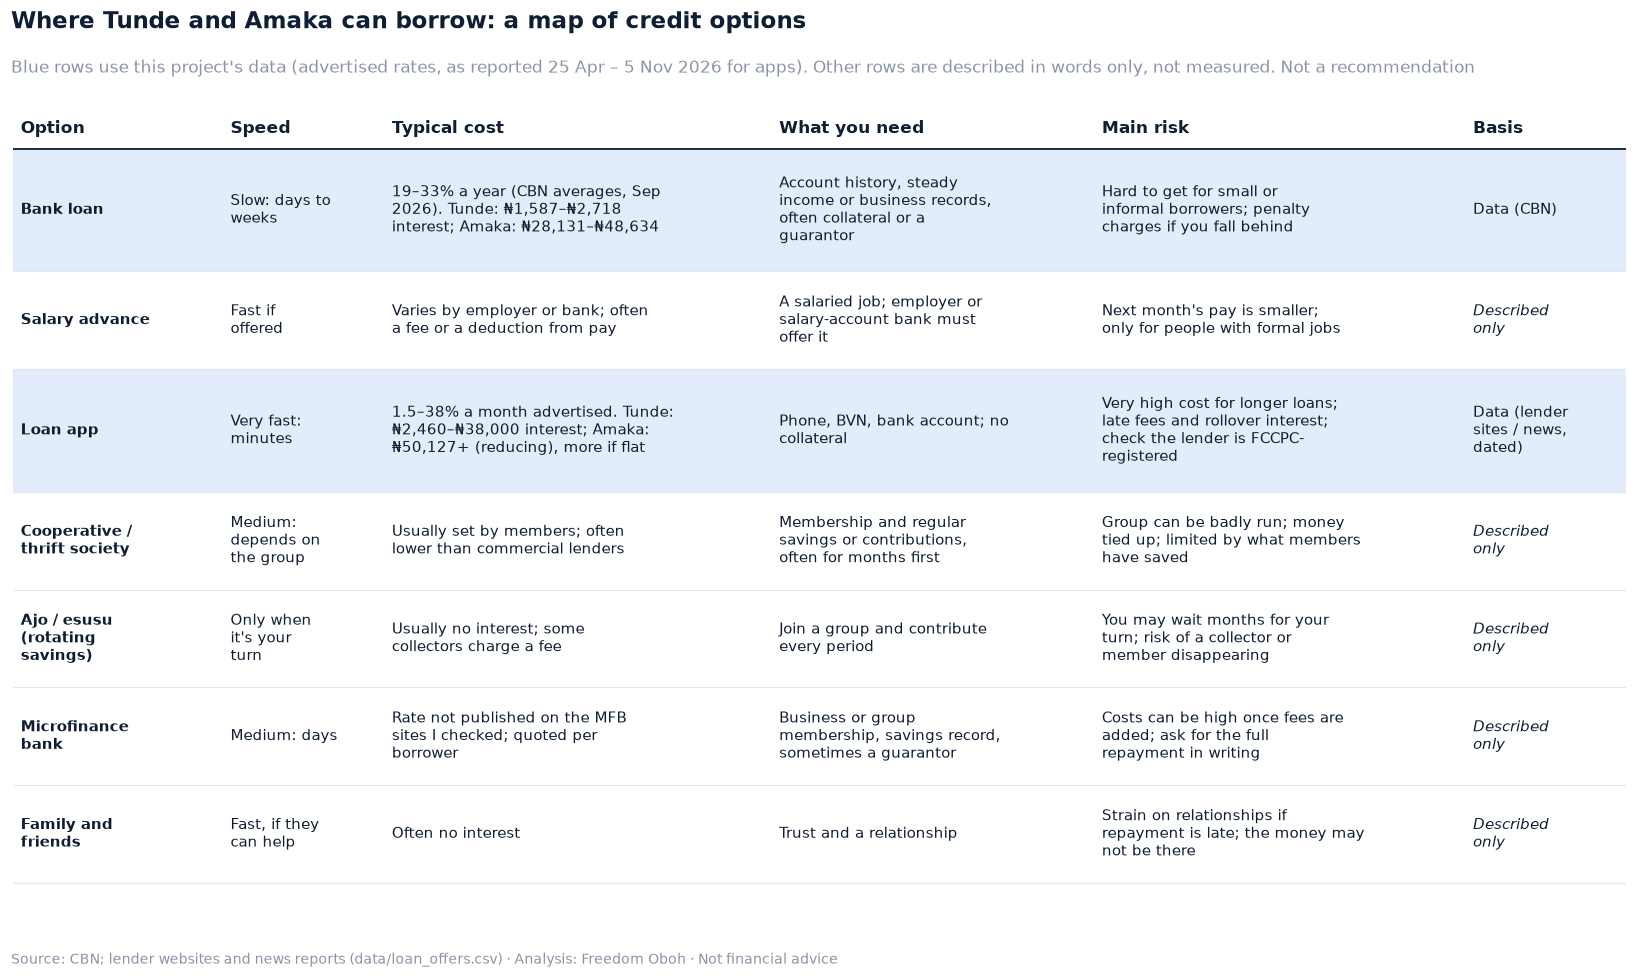

In [47]:
import textwrap

col_widths = [0.13, 0.10, 0.24, 0.20, 0.23, 0.10]
wrap_chars = [16, 13, 34, 28, 32, 13]
rows = [[textwrap.fill(str(v), w) for v, w in zip(r, wrap_chars)] for r in options.values]
heights = [max(c.count("\n") + 1 for c in r) for r in rows]

fig_h = 1.6 + 0.24 * sum(heights) + 0.25 * len(rows)
fig, ax = plt.subplots(figsize=(15, fig_h))
ax.axis("off")
ax.set_xlim(0, 1)
total_units = sum(heights) + 0.9 * len(rows) + 1.6
unit = 1 / total_units
y = 1
xs = np.cumsum([0] + col_widths[:-1])

for x, w, h in zip(xs, col_widths, options.columns):
    ax.text(x + 0.005, y - unit * 0.8, h, fontsize=11, fontweight="bold", color=style.NAVY, va="center")
y -= unit * 1.6
ax.plot([0, 1], [y, y], color=style.NAVY, linewidth=1.2)

for r, h, src in zip(rows, heights, options["Basis"]):
    row_h = unit * (h + 0.9)
    is_data = src.startswith("Data")
    if is_data:
        ax.add_patch(plt.Rectangle((0, y - row_h), 1, row_h, color=style.PALE_BLUE, alpha=0.6, linewidth=0))
    for i, (x, cell) in enumerate(zip(xs, r)):
        ax.text(x + 0.005, y - row_h / 2, cell, fontsize=9.6, va="center", color=style.NAVY,
                fontweight="bold" if i == 0 else "normal",
                style="italic" if (i == 5 and not is_data) else "normal")
    y -= row_h
    ax.plot([0, 1], [y, y], color=style.LIGHT_GREY, linewidth=0.8)

style.titles(fig, ax, "Where Tunde and Amaka can borrow: a map of credit options",
             f"Blue rows use this project's data ({REPORTED} for apps). Other rows are described in words only, not measured. Not a recommendation")
style.finish(fig, "07_credit_options_map.png",
             source="Source: CBN; lender websites and news reports (data/loan_offers.csv) · Analysis: Freedom Oboh · Not financial advice",
             top=0.90)
plt.show()

**What this means for Tunde and Amaka.** No option is fast, cheap *and* open to everyone.

- **Tunde.** He has a salary, so a salary advance may exist for him. A bank is cheap on paper but slow. An app is fast, and Chapter 6 compares a typical starting app rate with a bank's maximum rate. The risk is a month that turns into three (Chapter 8).
- **Amaka.** She runs a shop with irregular records and probably no collateral, so the cheap bank rate is the hardest door to open. Cooperatives and ajo can be cheaper, but they ask her to save first or wait her turn. Six months on an app is the most expensive path in this project's data.

This is the trade-off the whole project points to: **the cheaper the credit, the harder it is to get.**

> **Under the hood: what's measured and what isn't.** Only two rows carry numbers from this project: banks (CBN averages, Chapter 1) and loan apps (dated, sourced advertised rates, Chapter 6). The other five rows are general descriptions and are marked "Described only". They come from how these options commonly work, not from data, and real terms vary a lot from one group, employer or MFB to another. I looked for published microfinance bank rates on the lenders' own websites (LAPO, Accion, Baobab and others); none I could reach printed a rate, so the MFB row has no number.

---
# Three more questions

The first seven chapters answered the brief. While building them, three more questions kept coming up, so I added a short chapter for each.

---
## Chapter 8: What happens when Tunde misses the due date?

**The app loan was for one month. What if his salary comes late, and one month becomes three?**

This is the part of quick loans I've seen hurt people most. The price on the first day is only half the story. The other half is what happens after the due date.

`data/loan_offers.csv` holds two penalty structures that lenders publish on their own websites:
- a **late fee of 0.03333% a day** on the overdue amount (one lender's personal loan page), and
- **rollover interest of 1% a day** on late repayments (another lender's FAQ).

A third path is common too: **rolling the loan over**, where you pay nothing and the whole amount becomes a new one-month loan at the same monthly rate.

Tunde borrows ₦100,000 for one month at his **typical mid app rate** from Chapter 6, so on the due date he owes the amount below. Then he can't pay for 90 days. I treat the 1% a day rollover as **simple interest on the amount due, not compounded**, which is the kinder assumption.

In [48]:
# The penalty rates come from data/loan_offers.csv. Check the file really says so before using them.
notes = " ".join(offers["fees_note"])
assert "0.03333% per day" in notes and "1% per day" in notes, "penalty wording not found in loan_offers.csv"
LATE_FEE_DAILY = 0.03333 / 100
ROLLOVER_DAILY = 1 / 100

T_MID, T_HIGH = TIERS["Tunde"]["mid"], TIERS["Tunde"]["high"]
due = loan_math.repayment(100_000, T_MID, 1)
days = np.arange(0, 91)
months_rolled = days // 30  # a rollover adds a new month of interest every 30 days

paths = pd.DataFrame({
    "Late fee 0.0333% a day": due * (1 + LATE_FEE_DAILY * days),
    f"Roll over monthly at the typical mid rate ({T_MID:g}%)": due * (1 + T_MID / 100) ** months_rolled,
    "Rollover interest 1% a day (simple)": due * (1 + ROLLOVER_DAILY * days),
    f"Roll over monthly at the highest advertised rate ({T_HIGH:g}%)":
        loan_math.repayment(100_000, T_HIGH, 1) * (1 + T_HIGH / 100) ** months_rolled,
}, index=pd.Index(days, name="days after the due date"))
ROLL_COL = "Rollover interest 1% a day (simple)"

print(f"Owed on the due date at Tunde's typical mid app rate: ₦{due:,.0f} "
      f"(at the highest advertised rate: ₦{loan_math.repayment(100_000, T_HIGH, 1):,.0f})")
paths.loc[[0, 30, 60, 90]].round(0).map(lambda v: f"₦{v:,.0f}")

Owed on the due date at Tunde's typical mid app rate: ₦108,250 (at the highest advertised rate: ₦138,000)


,Late fee 0.0333% a day,Roll over monthly at the typical mid rate (8.25%),Rollover interest 1% a day (simple),Roll over monthly at the highest advertised rate (38%)
days after the due date,,,,
0,"₦108,250","₦108,250","₦108,250","₦138,000"
30,"₦109,332","₦117,181","₦140,725","₦190,440"
60,"₦110,415","₦126,848","₦173,200","₦262,807"
90,"₦111,497","₦137,313","₦205,675","₦362,674"


After 90 days: from ₦111,497 to ₦362,674, depending on how the lender charges.
With rollover interest of 1% a day, charged as simple interest on the amount due (the kinder assumption), the debt is ₦205,675: 2.1x what he borrowed.
If the 1% a day compounded daily instead, it would be ₦265,064 after 90 days (2.7x). Notebook only: the README uses the simple figure.


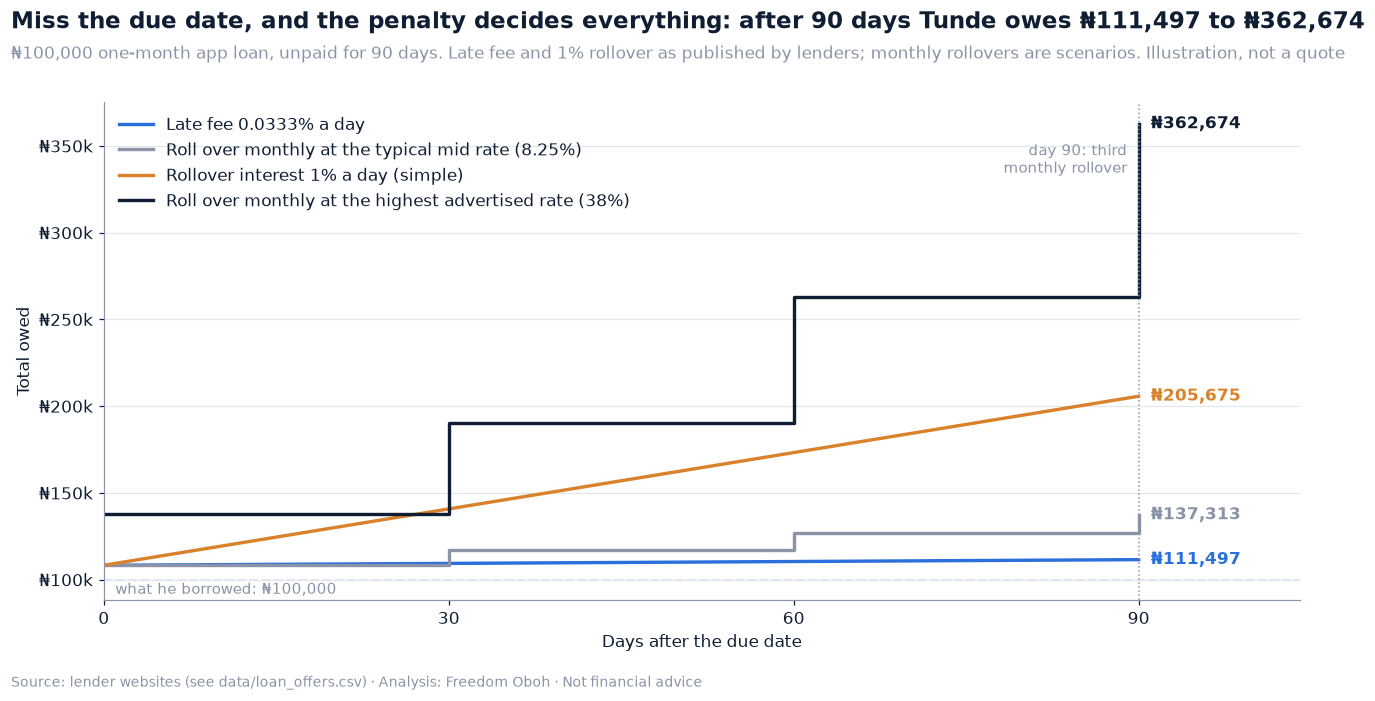

In [49]:
after90 = paths.loc[90]
spiral_low, spiral_high = after90.min(), after90.max()
print(f"After 90 days: from ₦{spiral_low:,.0f} to ₦{spiral_high:,.0f}, depending on how the lender charges.")
print(f"With rollover interest of 1% a day, charged as simple interest on the amount due (the kinder assumption), "
      f"the debt is ₦{after90[ROLL_COL]:,.0f}: {after90[ROLL_COL] / 100_000:.1f}x what he borrowed.")
roll_compound = due * (1 + ROLLOVER_DAILY) ** 90
print(f"If the 1% a day compounded daily instead, it would be ₦{roll_compound:,.0f} after 90 days "
      f"({roll_compound / 100_000:.1f}x). Notebook only: the README uses the simple figure.")

fig, ax = plt.subplots(figsize=(12, 6.3))
line_colors = [style.BLUE, style.GREY, style.ORANGE, style.NAVY]
for (name, s), c in zip(paths.items(), line_colors):
    drawstyle = "steps-post" if "Roll over" in name else "default"
    ax.plot(s.index, s.values, color=c, linewidth=2.2, drawstyle=drawstyle, label=name)
    ax.annotate(f"₦{s.iloc[-1]:,.0f}", xy=(90, s.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=11, fontweight="bold", color=c)
ax.axhline(100_000, color=style.LIGHT_GREY, linewidth=1.5, linestyle="--")
ax.text(1, 98_500, "what he borrowed: ₦100,000", fontsize=10, color=style.GREY, va="top")
ax.set_ylim(88_000, None)
ax.axvline(90, color=style.GREY, linewidth=1, linestyle=":")
ax.text(89, spiral_high * 0.97, "day 90: third\nmonthly rollover", ha="right", va="top", fontsize=9.5, color=style.GREY)
ax.set_xlim(0, 104)
ax.set_xticks([0, 30, 60, 90])
ax.set_xlabel("Days after the due date")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"₦{v / 1000:,.0f}k"))
ax.set_ylabel("Total owed")
ax.legend(loc="upper left")
style.titles(fig, ax,
             f"Miss the due date, and the penalty decides everything: after 90 days Tunde owes ₦{spiral_low:,.0f} to ₦{spiral_high:,.0f}",
             "₦100,000 one-month app loan, unpaid for 90 days. Late fee and 1% rollover as published by lenders; "
             "monthly rollovers are scenarios. Illustration, not a quote")
style.finish(fig, "08_debt_spiral.png",
             source="Source: lender websites (see data/loan_offers.csv) · Analysis: Freedom Oboh · Not financial advice")
plt.show()

**What this means for Tunde.** A late fee of a few naira a day is an annoyance. Rollover interest of 1% a day, or rolling the loan into a new month again and again, is a trap: in three months the debt can be close to double what he borrowed, or more. This is the pattern I saw in real life: the first month was affordable, and the months after it weren't. The general lesson: **before you borrow, read what happens after the due date, not just the rate on day one.**

> **Under the hood: penalty assumptions.**
> - Both daily penalties are applied as **simple** interest on the amount due on the due date, the kinder assumption. If a lender charges them on a growing balance (compounding daily), the debt grows faster: the output above shows the compounded figure for the 1% a day rollover.
> - The rollover paths assume a full new month of interest every 30 days on the whole amount, which is how a rollover usually works. Real terms vary by lender and by loan.
> - The penalty rates come from two lenders' own websites, and the code checks the wording is in `data/loan_offers.csv` before using them. I don't name or rank lenders here.
> - Under the FCCPC's 2025 regulations, lenders must disclose all fees before you borrow. Debt collection practices are also regulated.

---
## Chapter 9: Up the stairs, down the slope? Hikes vs cuts

**When the CBN raises its rate, does Amaka's loan get dearer quickly, but when the CBN cuts, does it get cheaper only slowly?**

Economists call this pattern "rockets and feathers": prices shoot up like a rocket and float down like a feather. It matters now, because the CBN cut the MPR in Sep 2026.

I rerun the Chapter 3 regression, but split each MPR change into **rises** and **cuts**, each with its own 0–12 month lags. Then I compare the cumulative pass-through of a 1-point rise with that of a 1-point cut.

In [50]:
rises = chg["policy_rate"].clip(lower=0)
cuts = chg["policy_rate"].clip(upper=0)   # negative numbers; a coefficient > 0 means the lending rate falls too
print(f"Rises: {(moves > 0).sum()} (total {moves[moves > 0].sum():.2f} points).  "
      f"Cuts: {(moves < 0).sum()} (total {moves[moves < 0].sum():.2f} points).")


def asym_pass_through(y_col):
    X = pd.concat({**{f"rise_lag{k}": rises.shift(k) for k in range(MAX_LAG + 1)},
                   **{f"cut_lag{k}": cuts.shift(k) for k in range(MAX_LAG + 1)}}, axis=1)
    data = pd.concat([chg[y_col], X], axis=1).dropna()
    m = sm.OLS(data[y_col], sm.add_constant(data.drop(columns=y_col))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    out = {}
    for kind in ["rise", "cut"]:
        rows = []
        for k in range(MAX_LAG + 1):
            cols = [f"{kind}_lag{j}" for j in range(k + 1)]
            se = np.sqrt(m.cov_params().loc[cols, cols].values.sum())
            rows.append({"months": k, "cumulative": m.params[cols].sum(), "se": se})
        out[kind] = pd.DataFrame(rows).set_index("months")
    w = pd.Series(0.0, index=m.params.index)
    w[[f"rise_lag{j}" for j in range(MAX_LAG + 1)]] = 1
    w[[f"cut_lag{j}" for j in range(MAX_LAG + 1)]] = -1
    diff = float(w @ m.params)
    diff_se = float(np.sqrt(w.values @ m.cov_params().values @ w.values))
    return out, diff, diff_se


asym, asym_diff, asym_diff_se = asym_pass_through("primeLending")
asym_max, asym_max_diff, asym_max_diff_se = asym_pass_through("maxLending")
tab = pd.DataFrame({
    "prime: after a rise": asym["rise"]["cumulative"], "prime: after a cut": asym["cut"]["cumulative"],
    "max: after a rise": asym_max["rise"]["cumulative"], "max: after a cut": asym_max["cut"]["cumulative"],
}).loc[[1, 3, 6, 9, 12]].round(2)
tab

Rises: 29 (total 29.25 points).  Cuts: 11 (total -15.25 points).


,prime: after a rise,prime: after a cut,max: after a rise,max: after a cut
months,,,,
1,0.24,-0.02,0.40,-0.35
3,0.23,0.04,0.22,0.08
6,0.35,0.03,0.29,-0.05
9,0.60,-0.01,0.42,-0.25
12,0.43,0.24,0.35,-0.02


In [51]:
up12, dn12 = asym["rise"].loc[MAX_LAG, "cumulative"], asym["cut"].loc[MAX_LAG, "cumulative"]
up6, dn6 = asym["rise"].loc[6, "cumulative"], asym["cut"].loc[6, "cumulative"]
up_se, dn_se = asym["rise"].loc[MAX_LAG, "se"], asym["cut"].loc[MAX_LAG, "se"]
asym_sig = abs(asym_diff) > 1.96 * asym_diff_se
print(f"Prime rate, 6 months after: rise {up6:.2f}, cut {dn6:.2f} points per 1-point MPR change.")
print(f"Prime rate, 12 months after: rise {up12:.2f} (±{1.96 * up_se:.2f}), cut {dn12:.2f} (±{1.96 * dn_se:.2f}).")
print(f"Difference (rise minus cut): {asym_diff:.2f}, ±{1.96 * asym_diff_se:.2f} -> "
      f"{'statistically clear' if asym_sig else 'NOT statistically clear'}.")
print(f"Maximum rate, 12 months after: rise {asym_max['rise'].loc[MAX_LAG, 'cumulative']:.2f}, "
      f"cut {asym_max['cut'].loc[MAX_LAG, 'cumulative']:.2f}.")

Prime rate, 6 months after: rise 0.35, cut 0.03 points per 1-point MPR change.
Prime rate, 12 months after: rise 0.43 (±0.25), cut 0.24 (±0.42).
Difference (rise minus cut): 0.19, ±0.55 -> NOT statistically clear.
Maximum rate, 12 months after: rise 0.35, cut -0.02.


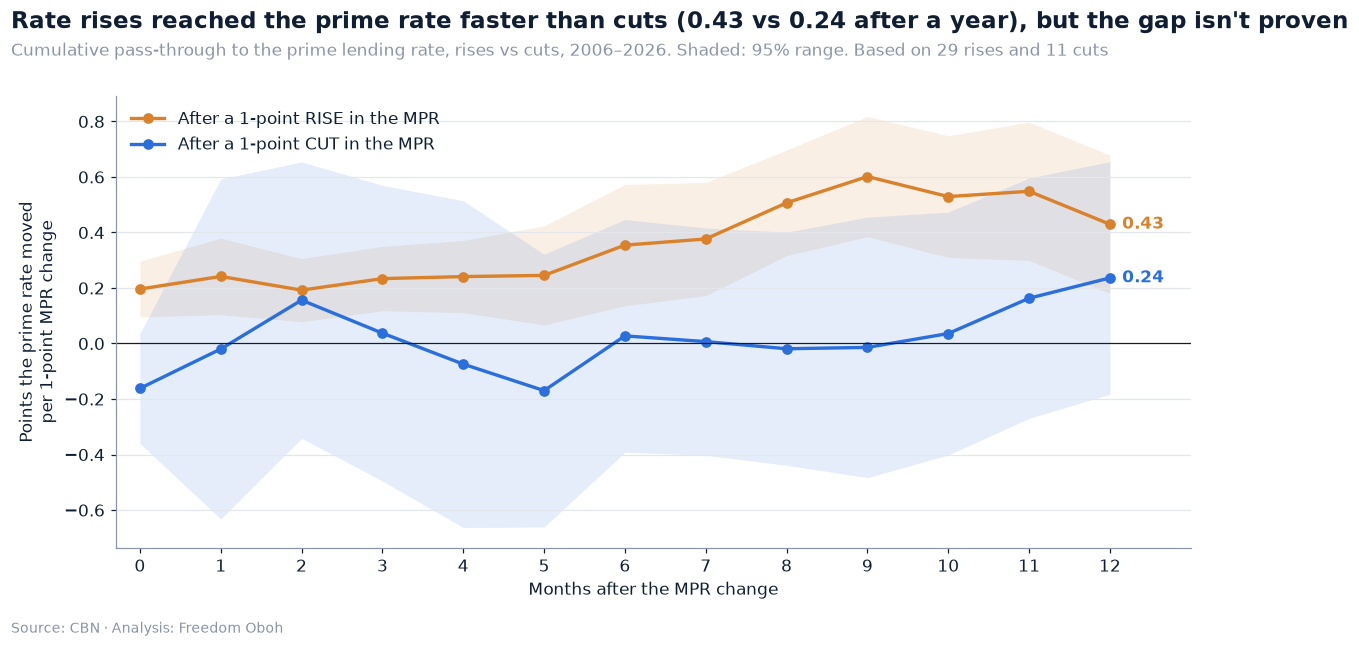

In [52]:
fig, ax = plt.subplots(figsize=(11, 5.8))
k = asym["rise"].index
for kind, c, lab in [("rise", style.ORANGE, "After a 1-point RISE in the MPR"), ("cut", style.BLUE, "After a 1-point CUT in the MPR")]:
    s = asym[kind]
    ax.fill_between(k, s["cumulative"] - 1.96 * s["se"], s["cumulative"] + 1.96 * s["se"], color=c, alpha=0.12, linewidth=0)
    ax.plot(k, s["cumulative"], color=c, marker="o", linewidth=2.2, label=lab)
    ax.annotate(f"{s['cumulative'].iloc[-1]:.2f}", xy=(k[-1], s["cumulative"].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=11, fontweight="bold", color=c)
ax.axhline(0, color=style.NAVY, linewidth=0.8)
ax.set_xticks(list(k))
ax.set_xlim(-0.3, 13)
ax.set_xlabel("Months after the MPR change")
ax.set_ylabel("Points the prime rate moved\nper 1-point MPR change")
ax.legend(loc="upper left")
style.titles(fig, ax,
             f"Rate rises reached the prime rate faster than cuts ({up12:.2f} vs {dn12:.2f} after a year), but the gap isn't proven",
             f"Cumulative pass-through to the prime lending rate, rises vs cuts, 2006–2026. Shaded: 95% range. "
             f"Based on {(moves > 0).sum()} rises and {(moves < 0).sum()} cuts")
style.finish(fig, "09_hikes_vs_cuts.png")
plt.show()

**What this means for Amaka.** The pattern fits "up the stairs, down the slope": after a rise, the prime rate moved up within months, while after a cut it barely moved for half a year. So the Sep 2026 cut is unlikely to make her loan cheaper soon. But I want to be honest about how sure this is. There were only 11 cuts in 20 years, and the gap between rises and cuts is **not statistically clear**: the data leans this way but can't prove it.

> **Under the hood: asymmetry test.** Same data and method as Chapter 3 (month-on-month changes, Dec 2006 instrument switch excluded, Newey–West standard errors), with MPR changes split into a "rises" series and a "cuts" series, each with lags 0–12. The test compares the 12-month sums for rises and cuts. With few cuts, the cut estimate is imprecise. A wide 95% range on the cut line means "we don't know much", not "cuts don't work".

---
## Chapter 10: Save first, or borrow now?

**What if Amaka didn't borrow? What if she saved for six months and then bought her stock?**

This links my savings project to this one. Waiting has a cost too: while she saves, prices rise, so ₦500,000 of stock today costs more in six months. Her savings earn a little interest, but in Nigeria, as the last project showed, usually less than inflation.

For every six-month window since 2006, I compare two costs, both as a % of ₦500,000:
- **Borrow now:** total interest on a ₦500,000 six-month bank loan at that month's **maximum lending rate** (reducing balance).
- **Save first:** she saves ₦500,000 ÷ 6 each month in a savings account at that month's savings rate. After six months, the extra she needs = the new price of the same stock − what she saved, interest included.

This compares naira only. It leaves out the biggest cost of waiting: **missing the festive season's sales**, which this data can't measure.

In [53]:
P = p["price_index"]
rows = []
for i in range(len(p) - 6):
    start = p.index[i]
    loan_rate_m = p["maxLending"].iloc[i] / 12
    sav_rate_m = p["savingsDeposit"].iloc[i] / 12 / 100
    borrow_cost = loan_math.reducing_total(500_000, loan_rate_m, 6) - 500_000
    saved = 0.0
    for _ in range(6):
        saved = (saved + 500_000 / 6) * (1 + sav_rate_m)
    wait_cost = 500_000 * P.iloc[i + 6] / P.iloc[i] - saved
    rows.append({"start": start, "borrow now": borrow_cost / 5_000, "save first": wait_cost / 5_000})
sb = pd.DataFrame(rows).set_index("start")   # % of ₦500,000

wait_cheaper = sb["save first"] < sb["borrow now"]
latest_start = sb.index[-1]
print(f"{len(sb)} six-month windows, starting {sb.index[0]:%b %Y} to {latest_start:%b %Y}.")
print(f"Saving first cost less than borrowing at the bank's maximum rate in {wait_cheaper.sum()} of them ({wait_cheaper.mean():.0%}).")
print(f"Latest window (from {latest_start:%b %Y}): borrow {sb['borrow now'].iloc[-1]:.1f}% vs save first "
      f"{sb['save first'].iloc[-1]:.1f}% of ₦500,000 "
      f"(₦{sb['borrow now'].iloc[-1] * 5_000:,.0f} vs ₦{sb['save first'].iloc[-1] * 5_000:,.0f}).")
print(f"Six months on a loan app at Amaka's typical mid rate today would cost {(AMAKA_PAY['Loan app: typical mid rate'] - 500_000) / 5_000:.1f}% "
      f"(app rates are only available for 2026, so they can't be compared across history).")
by_year = (~wait_cheaper).groupby(sb.index.year).mean()
borrow_years = list(by_year[by_year > 0.5].index)
def year_runs(years):
    # [2008, 2022, 2023, 2024] -> "2008 and 2022–2024"
    runs, start = [], None
    for i, y in enumerate(years):
        start = y if start is None else start
        if i == len(years) - 1 or years[i + 1] != y + 1:
            runs.append(f"{start}–{y}" if y != start else f"{y}")
            start = None
    return runs[0] if len(runs) == 1 else ", ".join(runs[:-1]) + " and " + runs[-1]

borrow_years_text = year_runs(borrow_years)
print(f"Years (by start month) when borrowing was cheaper in most windows: {borrow_years_text}")
worst_wait = sb["save first"].idxmax()
print(f"Waiting was costliest for windows starting {worst_wait:%b %Y}: {sb['save first'].max():.1f}% of ₦500,000.")

243 six-month windows, starting Jan 2006 to Mar 2026.
Saving first cost less than borrowing at the bank's maximum rate in 199 of them (82%).
Latest window (from Mar 2026): borrow 10.5% vs save first 5.4% of ₦500,000 (₦52,524 vs ₦26,784).
Six months on a loan app at Amaka's typical mid rate today would cost 30.8% (app rates are only available for 2026, so they can't be compared across history).
Years (by start month) when borrowing was cheaper in most windows: 2022–2024
Waiting was costliest for windows starting Jan 2024: 13.9% of ₦500,000.


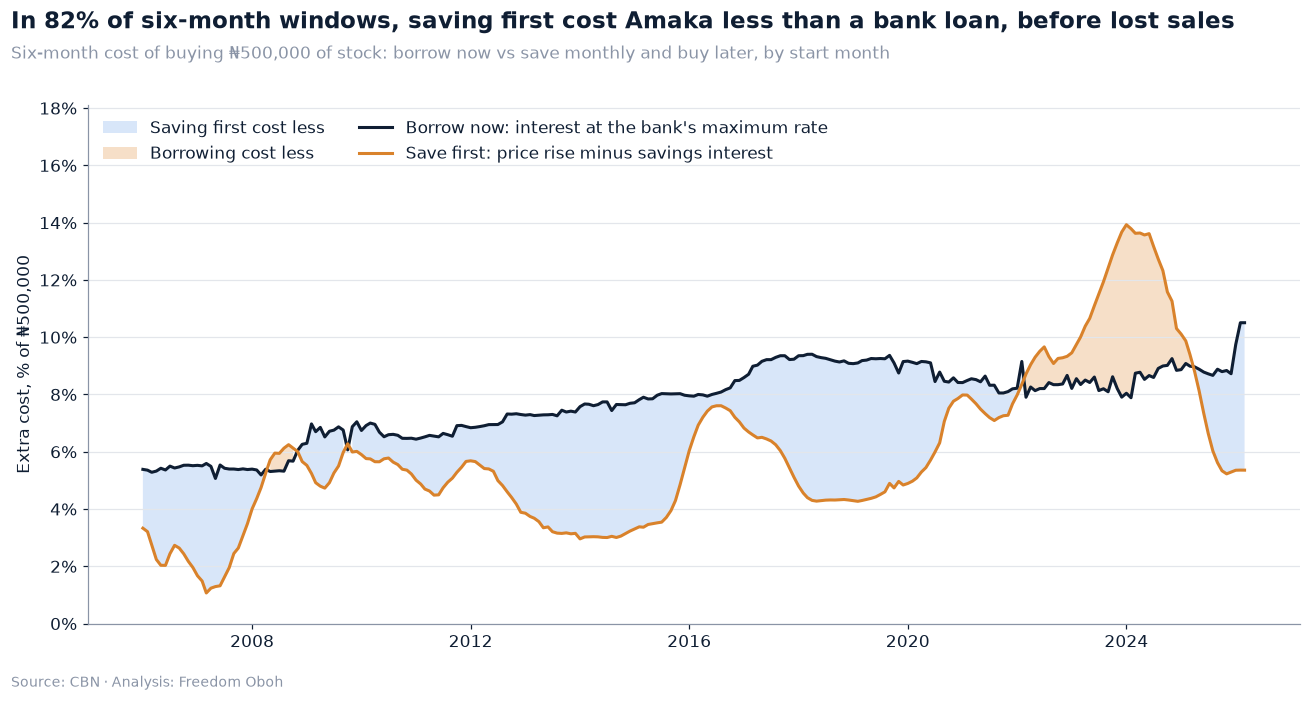

In [54]:
fig, ax = plt.subplots(figsize=(12, 6.3))
ax.fill_between(sb.index, sb["save first"], sb["borrow now"], where=wait_cheaper, color=style.PALE_BLUE, alpha=0.8,
                linewidth=0, label="Saving first cost less")
ax.fill_between(sb.index, sb["save first"], sb["borrow now"], where=~wait_cheaper, color=style.PALE_ORANGE, alpha=0.9,
                linewidth=0, label="Borrowing cost less")
ax.plot(sb.index, sb["borrow now"], color=style.NAVY, linewidth=2, label="Borrow now: interest at the bank's maximum rate")
ax.plot(sb.index, sb["save first"], color=style.ORANGE, linewidth=2, label="Save first: price rise minus savings interest")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.yaxis.set_major_locator(mticker.MultipleLocator(2))
ax.set_ylabel("Extra cost, % of ₦500,000")
ax.set_ylim(0, max(sb.max()) * 1.3)
ax.legend(loc="upper left", ncols=2)
style.titles(fig, ax,
             f"In {wait_cheaper.mean():.0%} of six-month windows, saving first cost Amaka less than a bank loan, before lost sales",
             "Six-month cost of buying ₦500,000 of stock: borrow now vs save monthly and buy later, by start month")
style.finish(fig, "10_save_vs_borrow.png")
plt.show()

**What this means for Amaka.** In naira alone, saving first was usually cheaper than a bank loan at the maximum rate. But not always: for loans starting in the high-inflation years listed above, prices rose so fast that waiting cost more than the loan's interest. And the naira figure leaves out what matters most to a trader: a provisions shop that misses the festive season loses its best weeks of sales. That's why people borrow even when it's expensive. The fair conclusion is that borrowing makes sense when the loan earns more than it costs, and only the borrower can judge that. This chart just puts a price on waiting.

> **Under the hood: save vs borrow.**
> - Prices use the chained monthly price index (Jan 2006 = 100). Savings use the CBN average savings deposit rate, compounded monthly on equal deposits. The loan uses the CBN average maximum lending rate for the start month, held for six months.
> - Each window uses only what was known or observed in that window. Overlapping windows are not independent.
> - Lost sales, fees, taxes and whether a bank would lend to Amaka at all are left out. Real stock prices can rise faster or slower than the general price index.

---
## Chapter 11: What I learned, and what to watch

The lessons below are written by the notebook itself, so every number comes straight from the analysis above.

In [55]:
from IPython.display import Markdown, display

lessons = f'''
**1. The price of a bank loan depends more on who you are than on what the CBN does.**
I expected the CBN's rate to set the price of credit. Over 20 years, banks passed on only about **{Y:.2f} points of every 1-point MPR change** to the prime rate within a year, and the link to the maximum rate was too weak to measure. Rises seemed to travel faster than cuts ({up12:.2f} vs {dn12:.2f} points after a year), though with only {(moves < 0).sum()} cuts that gap isn't proven. Meanwhile the gap between the best and worst bank rates grew from **{g_first:.1f} to {g_last:.1f} points**. For Amaka, being "small" costs more than any CBN decision.

**2. Savers lost every month. Borrowers didn't come out ahead every month.**
In my savings project, saving lost to inflation. Here, savers lost to inflation in **{neg_sav} months**, all of them, but prime-rate borrowers came out ahead (inflation was higher than the loan rate) in only **{neg_prime} months**, almost all from {longest['from']:%Y} to {longest['to']:%Y}. The bank's margin sits between the two. Today a small borrower near the maximum rate pays about **{r_max_last:.1f}% a year above inflation**.

**3. Government moved up the queue.**
Government's share of domestic credit went from **{sh_first:.0f}% to {sh_last:.0f}%**, and in real naira, credit to businesses and households is back to its **{back_to:%Y}** level. In {tb_beats_prime.sum()} months of 2024–25, a T-bill paid a bank as much as or more than lending to its best customers. The link between high T-bill rates and slower private credit is real but weak (r = {best_r:.2f}). That is not proof of crowding out, but it is a pattern worth watching.

**4. The fast money is priced by the month, and that hides how expensive it is.**
Advertised loan app rates run from about **{ADV_MIN:g}% to {ADV_MAX:g}% a month**. That sounds small until you multiply it out: Tunde's typical mid rate, {TIERS['Tunde']['mid']:.2f}% a month, is about **{loan_math.effective_annual(TIERS['Tunde']['mid']):.0f}% a year** compounded. {APP_VS_BANK_SENTENCE} Stretch it to six months like Amaka's, add flat interest, and the bill climbs fast. And the real danger comes after the due date: with rollover interest of 1% a day (simple, not compounded), Tunde's ₦100,000 becomes **₦{after90[ROLL_COL]:,.0f} in 90 days**.

**5. The cheaper the credit, the harder it is to get.**
That's the whole story in one line. The bank is cheapest but slowest and hardest to qualify for. The app is fastest and open to almost anyone, and the most expensive. Cooperatives and ajo can be cheap, but they ask you to save first or wait your turn. Even saving first has a price: it was cheaper than a bank loan in **{wait_cheaper.mean():.0%}** of six-month windows, but it costs a trader the season she was borrowing for.
'''
display(Markdown(lessons))


**1. The price of a bank loan depends more on who you are than on what the CBN does.**
I expected the CBN's rate to set the price of credit. Over 20 years, banks passed on only about **0.35 points of every 1-point MPR change** to the prime rate within a year, and the link to the maximum rate was too weak to measure. Rises seemed to travel faster than cuts (0.43 vs 0.24 points after a year), though with only 11 cuts that gap isn't proven. Meanwhile the gap between the best and worst bank rates grew from **1.5 to 13.6 points**. For Amaka, being "small" costs more than any CBN decision.

**2. Savers lost every month. Borrowers didn't come out ahead every month.**
In my savings project, saving lost to inflation. Here, savers lost to inflation in **249 months**, all of them, but prime-rate borrowers came out ahead (inflation was higher than the loan rate) in only **72 months**, almost all from 2020 to 2025. The bank's margin sits between the two. Today a small borrower near the maximum rate pays about **15.7% a year above inflation**.

**3. Government moved up the queue.**
Government's share of domestic credit went from **17% to 32%**, and in real naira, credit to businesses and households is back to its **2008** level. In 11 months of 2024–25, a T-bill paid a bank as much as or more than lending to its best customers. The link between high T-bill rates and slower private credit is real but weak (r = -0.24). That is not proof of crowding out, but it is a pattern worth watching.

**4. The fast money is priced by the month, and that hides how expensive it is.**
Advertised loan app rates run from about **1.5% to 38% a month**. That sounds small until you multiply it out: Tunde's typical mid rate, 8.25% a month, is about **159% a year** compounded. A good app offer can cost about the same as a bank loan at the maximum rate: a typical starting app rate of 2.46% a month for Tunde and 2.80% for Amaka, against 2.72% at the bank. The real danger is the highest advertised rates and what happens after the due date. Stretch it to six months like Amaka's, add flat interest, and the bill climbs fast. And the real danger comes after the due date: with rollover interest of 1% a day (simple, not compounded), Tunde's ₦100,000 becomes **₦205,675 in 90 days**.

**5. The cheaper the credit, the harder it is to get.**
That's the whole story in one line. The bank is cheapest but slowest and hardest to qualify for. The app is fastest and open to almost anyone, and the most expensive. Cooperatives and ajo can be cheap, but they ask you to save first or wait your turn. Even saving first has a price: it was cheaper than a bank loan in **82%** of six-month windows, but it costs a trader the season she was borrowing for.


### My own view, as a former credit risk analyst

I once worked as a credit risk analyst. My day-to-day was assessing loans for SMEs, individuals and corporations, and I saw a lot of bias in who got approved. I also know many people who took quick loans, and when they defaulted the interest grew so fast that paying back became impossible. This project put numbers on what I saw: the price of credit in Nigeria is set less by the cost of money than by who the lender thinks you are, and the people with the fewest options pay the most per month.

### What to watch

- **MPR decisions.** On 22 Sep 2026 the CBN cut the MPR by 350 basis points to 23%, the biggest cut since 2006 ([Nairametrics, 22 Sep 2026](https://nairametrics.com/2026/09/22/cbn-resets-mpr-by-350-basis-points-to-23-biggest-cut-since-2006/)). The Sep 2026 prime rate in this data mostly reflects the period before the cut. Chapters 3 and 9 suggest only part of any cut will reach borrowers, and slowly.
- **Inflation.** When inflation falls faster than lending rates, real borrowing costs rise. That's what happened in 2026 (Chapter 2).
- **T-bill rates.** If government keeps paying close to the prime rate, banks have less reason to lend to small businesses (Chapter 5).
- **Credit to the private sector, in real terms.** Nominal growth can hide a real fall (Chapter 4).
- **FCCPC enforcement.** Whether loan apps actually publish their rates on their websites, as the 2025 regulations require, and whether the "not exploitative" rule is ever turned into action (Chapter 6).

**This is a historical data analysis and a learning project, not financial advice.**

In [56]:
# Save the clean data and every figure the README uses, so the README is filled only from notebook output
import json

PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(exist_ok=True)
panel.to_csv(PROCESSED / "monthly_panel.csv", index=False)
real.join(real_cr).to_csv(PROCESSED / "real_rates_and_credit.csv")
repay.to_csv(PROCESSED / "repayment_scenarios.csv")
options.to_csv(PROCESSED / "credit_options_map.csv", index=False)

f2 = lambda v: round(float(v), 2)
numbers = {
    "first_month": f"{FIRST:%b %Y}", "last_month": f"{LAST:%B %Y}", "last_month_short": f"{LAST:%b %Y}",
    "n_months": int(n),
    # chapter 1
    "prime_last": f2(prime_last), "max_last": f2(max_last), "prime_first": f2(prime_first), "max_first": f2(max_first),
    "gap_first": round(float(g_first), 1), "gap_last": round(float(g_last), 1),
    "gap_peak": round(float(g_peak), 1), "gap_peak_month": f"{g_peak_month:%b %Y}",
    # chapter 2
    "neg_prime": int(neg_prime), "neg_prime_share": f"{neg_prime / n:.0%}", "neg_max": int(neg_max), "neg_sav": int(neg_sav),
    "longest_run": int(longest["months"]), "longest_from": f"{longest['from']:%b %Y}", "longest_to": f"{longest['to']:%b %Y}",
    "real_low": round(float(low_val), 1), "real_low_month": f"{low_month:%b %Y}",
    "real_prime_last": round(float(r_prime_last), 1), "real_max_last": round(float(r_max_last), 1),
    "inflation_last": f2(p["inflation"].iloc[-1]), "bank_margin_avg": round(float((p["primeLending"] - p["savingsDeposit"]).mean()), 1),
    # chapter 3
    "mpr_last": f2(p["mpr"].iloc[-1]), "mpr_moves": int(len(moves)),
    "mpr_last_change_bp": round(float(chg["policy_rate"].iloc[-1] * 100)),
    "mpr_cut_bp": abs(round(float(chg["policy_rate"].iloc[-1] * 100))),
    "mpr_last_cut_biggest": bool(chg["policy_rate"].iloc[-1] < 0 and chg["policy_rate"].iloc[-1] <= chg["policy_rate"].min()),
    "cycle_start": f"{cycle_start:%b %Y}", "cycle_end": f"{cycle_end:%b %Y}", "cycle_after": f"{after:%b %Y}",
    "cycle_mpr_rise": round(float(X), 1), "cycle_prime_rise": round(float(prime_move_after), 1),
    "cycle_prime_share": f"{prime_move_after / X:.0%}", "cycle_max_rise": round(float(max_move_after), 1),
    "pt_prime": f2(Y), "pt_prime_low": f2(prime_pt.loc[MAX_LAG, "low"]), "pt_prime_high": f2(prime_pt.loc[MAX_LAG, "high"]),
    "pt_prime_pct": f"{Y:.0%}", "pt_half_months": int(Z), "pt_max": f2(max_pt.loc[MAX_LAG, "cumulative"]),
    "pt_r2": round(float(prime_model.rsquared), 2),
    # chapter 4
    "gov_share_first": round(float(sh_first), 1), "gov_share_last": round(float(sh_last), 1),
    "gov_neg_months": int(gov_neg.sum()), "gov_neg_from": f"{cr.index[gov_neg].min():%b %Y}",
    "gov_neg_to": f"{cr.index[gov_neg].max():%b %Y}",
    "private_tn_last": f2(cr["creditToPrivateSector"].iloc[-1] / 1e6), "gov_tn_last": f2(cr["creditToGovernment"].iloc[-1] / 1e6),
    "private_tn_first": f2(cr["creditToPrivateSector"].iloc[0] / 1e6),
    "private_nominal_x": round(float(nominal_multiple)), "price_x": round(float(price_multiple), 1),
    "real_private_back_to": f"{back_to:%b %Y}", "real_private_back_to_year": f"{back_to:%Y}",
    # chapter 5
    "tbill_last": f2(tb.iloc[-1]), "tbill_prime_gap_avg": round(float(spread.mean()), 1),
    "tbill_prime_gap_last": round(float(spread.iloc[-1]), 1), "tbill_beats_prime": int(tb_beats_prime.sum()),
    "crowd_lag": int(best_lag), "crowd_r": f2(best_r), "crowd_r_2010": f2(r_2010), "crowd_r2": f"{best_r ** 2:.0%}",
    # chapter 6
    "n_products": int(len(offers)), "n_lenders": int(offers["lender"].str.split(" ").str[0].nunique()),
    "n_lender_site": int(from_lender.sum()), "n_news": int((~from_lender).sum()),
    "lender_site_names": ", ".join(offers.loc[from_lender, "lender"].str.split(" ").str[0].drop_duplicates()),
    "news_names": ", ".join(offers.loc[~from_lender, "lender"].str.split(" ").str[0].drop_duplicates()),
    "adv_min": float(ADV_MIN), "adv_max": float(ADV_MAX),
    **{f"{who.lower()}_rate_{k}": f2(v) for who in TIERS for k, v in TIERS[who].items()},
    "tunde_mid_effective": round(float(loan_math.effective_annual(TIERS["Tunde"]["mid"]))),
    "bank_prime_monthly": f2(BANK_PRIME_M), "bank_max_monthly": f2(BANK_MAX_M),
    **{f"tunde_{k}": round(float(v)) for k, v in zip(["prime", "max", "app_start", "app_mid", "app_high"], TUNDE_PAY)},
    **{f"amaka_{k}": round(float(v)) for k, v in zip(["prime", "max", "app_start", "app_mid", "app_high"], AMAKA_PAY)},
    "app_vs_bank_sentence": APP_VS_BANK_SENTENCE,
    "cheap_not_1m": cheap_names,
    "amaka_mid_red": round(float(mid_red)), "amaka_mid_flat": round(float(mid_flat)), "amaka_flat_extra": round(float(mid_flat - mid_red)),
    "amaka_flat_extra_pct": f"{(mid_flat - 500_000) / (mid_red - 500_000) - 1:.0%}",
    "carbon_example": round(float(carbon_example)),
    # chapter 8: debt spiral
    "due_mid": round(float(due)), "spiral_low": round(float(spiral_low)), "spiral_high": round(float(spiral_high)),
    "spiral_rollover_1pct": round(float(after90[ROLL_COL])),
    "spiral_rollover_mid": round(float(after90.iloc[1])),
    "spiral_multiple": round(float(after90[ROLL_COL] / 100_000), 1),
    "tunde_mid_rate_label": f"{T_MID:g}", "tunde_high_rate_label": f"{T_HIGH:g}",
    # chapter 9: hikes vs cuts
    "n_rises": int((moves > 0).sum()), "n_cuts": int((moves < 0).sum()),
    "pt_rise_12": f2(up12), "pt_cut_12": f2(dn12), "pt_rise_6": f2(up6), "pt_cut_6": f2(dn6),
    "asym_diff": f2(asym_diff), "asym_diff_ci": f2(1.96 * asym_diff_se), "asym_sig": bool(asym_sig),
    # chapter 10: save vs borrow
    "sb_windows": int(len(sb)), "sb_wait_cheaper": int(wait_cheaper.sum()), "sb_wait_cheaper_pct": f"{wait_cheaper.mean():.0%}",
    "sb_latest_start": f"{latest_start:%b %Y}", "sb_borrow_last": round(float(sb["borrow now"].iloc[-1]), 1),
    "sb_wait_last": round(float(sb["save first"].iloc[-1]), 1),
    "sb_borrow_years": borrow_years_text,
    # data checks
    "tbill_zero_months": ", ".join(mm.loc[mm["treasuryBill_zero_fixed"], "month"].dt.strftime("%b %Y")),
    "credit_missing_months": ", ".join(clean.missing_months(credit, FIRST, LAST).strftime("%b %Y")),
    "spot_check_all_match": bool(spot["match"].all()),
}
(PROCESSED / "readme_numbers.json").write_text(json.dumps(numbers, indent=1, ensure_ascii=False), encoding="utf-8")
print(f"Saved {len(numbers)} figures to data/processed/readme_numbers.json, plus 4 processed CSVs.")
print(f"Spot-checks all match: {numbers['spot_check_all_match']}")
print(f"Check against the cited MPR cut: change in {LAST:%b %Y} = {numbers['mpr_last_change_bp']} basis points to "
      f"{numbers['mpr_last']}%; biggest cut in the series since {FIRST:%Y}: {numbers['mpr_last_cut_biggest']}")

Saved 125 figures to data/processed/readme_numbers.json, plus 4 processed CSVs.
Spot-checks all match: True
Check against the cited MPR cut: change in Sep 2026 = -350 basis points to 23.0%; biggest cut in the series since 2006: True
